# **STEP 4, PART 1** 

## **The grid search with the north-south asymmetry (motion fitted, CGM difference fixed)**

### **The same grid search as step 3, with the asymmetry of `mw_cube.py` switched on: `v_motion` is fitted on top of the fixed CGM difference (Oprea et al.).**

*This notebook is `grid_search_4d.ipynb` (step 3) with the settings of this stage. The flow, the residuals, the fit and the three checks are unchanged. What is different:*

| | |
|---|---|
| **This notebook** | stage `B1` (check stage `PB1`, next stage `B2`); run file `runs/grid4d_B1.json`; seeds 20000 ... 20511 (`PB1`: 21000 ..., `B2`: 24000 ...), none of them used by G1 (10000 ..., P1 14000 ..., G2 12000 ...) |
| **Parameters** | **fitted:** `hv0`, `alpha_conds`, `alpha_hv`, `f_ion` **and `v_motion`** (-60 ... +20 km/s) |
| **Fixed asymmetry** | the three `south_*_ratio` of the settings cell (from the temperature difference of Oprea et al.), the same in every run |
| **The model** | `mw_cube.create_cube_MW_asym`: the north is a north-type run (`z > 0`), the south is a north-type run with the south parameters that is flipped in `b` and stitched to the north. Both are launched from the same random numbers, so their difference is the physics. **Every run costs twice a symmetric run** (time; the estimate below includes it) |
| **Where things go** | `results_B1/` holds the caches of this stage (the caches of G1 in `results/` are not touched); `out_B1_*/` the packs |
| **New sections** | 5b (this fit against the symmetric fit of G1), 6.4 (what does `v_motion` take from the other parameters?) |

*A model run that has no asymmetry at all is bit-identical to the one of step 3 (`asymmetry_checks.ipynb` checks that and everything else about the asymmetry).*

**What this notebook does:** It designs the model grid, tells exactly which parameters every run will use, prepares the run file for `heron`, and after the runs it reads the packed grid (`pack.fits`), evaluates *every* residual of the convergence study on every model, and fits one surface per residual, so that the study shows where each residual puts the best parameters and how sure it is.

**The flow, in order:** It can be stopped after each step and resumed due to robust caching.

| step | where | what | needs |
|---|---|---|---|
| 1. Design | here | the box, the Sobol design, **the full parameter list of every run**, the run file `runs/grid4d_<STAGE>.json`, time and memory estimate | nothing but this folder |
| 2. Run | `heron` | `condor_submit <submit_file>.sub` (the job runs the models **and packs them by itself**) | the run file on `heron` |
| 3. Bring | here | copy `pack.fits` (+ two small files), check that the models are the ones the run file lists | the files from step 2 |
| 4. Evaluate | here | LAB side as in the convergence study; all residuals on all models | LAB, the pack |
| 5. Fit | here | one surface and one optimum per residual, compared | the evaluations |
| 6. Three checks | here (+ one short job on `heron` for the direct test of check 3) | north against south, a mock sky with a known answer, Marasco's point in our surface | the fit; for check 3b a job of 80 runs, stage `PB1` |
| 7. Next stage | here | (optional) the next batch of runs, then back to step 1 with a new `STAGE` | the fits |

In this notebook, **every run file lists all parameters**, step 1 prints them, `heron_job.py` writes down what it actually used (`params_effective.csv`), the pack stores them too, and step 3 compares the three.

**The observable:** Not a log-likelihood any more, like the first attempt.

The residuals of the convergence study (`abs`, `sq`, `rel` in three sets: base = soft floor, `Mrsc` = Marasco's 0.04 K selection, `Li` = $k\sigma$ selection with the blanks penalty, default `k=2`). Smaller $R$ is better. 

A fit needs a quantity to maximise with known noise, so for every residual key the surface is fitted to $y = -\ln R / s_{\rm ref}$, where $s_{\rm ref}$ is the relative seed-to-seed scatter of that residual at $n = 40$ (convergence study). One unit of $y$ is then the noise of one reference run, and the noise of a run at other $n$ is $s(n)/s_{\rm ref}$. The surfaces of different residuals live on different scales, so we compare their **optima**, not their values.

## 0. Settings

In [ ]:
import sys, re, time, json, pickle
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

sys.path.insert(1, "../EPG_Code/current_version_software")
sys.path.insert(1, "../EPG_Code/mw_addenda")
sys.path.insert(1, "../EPG_Code/fitting")

import grid_search as g
import grid_search_residuals as gr
import pack_grid as pg

# ---------------- where things are ----------------
WORK        = Path("./")                       # local copy of the heron working folder
LAB_PATH    = "../Displays/lab.fit.gz"
PRODUCTS    = "../Convergence/lab_products.npz"
SFR_PROFILE = "../Tests/inputs/sfr_profile_marasco12.txt"
CONV        = Path("../Convergence/conv")      # the convergence-study cubes and their cache (for the noise of each residual)
WORKERS     = 10                               # processes for evaluating the pack on this computer
HERON_WORK  = "<redacted_for_privacy>"

# ---------------- the stage ----------------
STAGE       = "B1"
N_PER_BIN   = 40        # particles per bin of the run (40 = the exploration setting of the convergence study)
N_POINTS    = 512       # Sobol points of this stage (a power of 2 keeps the design balanced!)
SEED0       = 20000     # seeds of this stage: SEED0 ... SEED0 + N_POINTS - 1 (G1 used 10000 ..., G2 12000 ..., P1 14000 ...)
HV0_MAX     = 120.0     # upper edge of hv0 (km/s)

# what one n = 40 run takes and needs: the longest run and the peak memory per worker of the G1 job itself 
# (out_G1_0/job_summary.json: 5.81 min, 788 MB,
# on a full 128-core machine; the single-run probe had said 2.88 min and 687 MB, 
# so the estimate below uses the numbers of the real job)
PROBE_MIN, PROBE_MB, PROBE_N = 5.81, 1050.0, 40   # the time is that of G1 (an asymmetric model is x2 in gr.job_estimate); the memory has +~260 MB for the second
                                                  # hemisphere and the stitched sky (an estimate: put the real number of the first job here)
FIT_STAGES  = ("B1", "B2")                                 # the stages whose models are fitted (the check stage P1 is not)

# The check stage for Marasco. See Section 6.3.
P1_STAGE, P1_N, P1_SEEDS, P1_SEED0 = "PB1", 40, 8, 21000   # seeds 21000 ... 21079 (the next stage B2 will use 24000 ...)

# ---------------- the asymmetry (step 4) ----------------
# Oprea et al. (2026) find a southern CGM that is hotter than the northern one (Delta T / T ~ 12 % in eROSITA; 13-20 % in their simulation)
# and a disk that moves relative to the CGM at up to ~40 km/s (towards the south). Theirs is a temperature difference; as a first conversion
# into the parameters of the model (to be refined with the paper in hand):
T_RATIO      = 1.12                    # T_south / T_north
GAMMA        = 5.0 / 3.0               # adiabatic index: density ~ T^(1 / (gamma - 1)) for adiabatic compression
RHO_RATIO    = T_RATIO ** (1.0 / (GAMMA - 1.0))     # = 1.185. Alternatives: 1 / T_RATIO (same pressure), 1.0 (no density difference)
SOUTH_RATIOS = dict(south_vlag_ratio=T_RATIO,       # vlag: the lag of the corona's rotation and the drag threshold ~ T
                    south_alpha_conds_ratio=RHO_RATIO,    # the condensation rate ~ density of the corona
                    south_drag_ratio=RHO_RATIO)           # the drag ~ density of the corona
V_MOTION_RANGE = (-60.0, 20.0)         # km/s. Corona moving towards the disk in the north run = +. Oprea et al.: about -40
V_MOTION_FIXED = -40.0                 # km/s: the value when v_motion is not fitted (Oprea et al.)

ASYM_FIXED   = dict(v_kick=0.0, v_motion_even=0.0, **SOUTH_RATIOS) 
# this notebook: the CGM difference is fixed, v_motion is fitted, v_motion_even is added later and bears no importance.

# ---------------- the comparison with LAB: the same settings as the convergence study ----------------
B_CUT, L_CUT = 0, 0
V_DEV      = 35.0                                          # km/s: |v_dev| below this is disc
REL_FLOOR  = 0.04                                          # K: soft floor of the base relative residual

In [2]:
from mw_io import load_npz, load_lab_products
from mw_display import Cube
from mw_cube import mirror_north_to_full_sky
from mw_mask import (disk_velocity_envelope, mask_disk_emission, mask_named_regions, flat_v_circ, 
                     OUTER_ARM, GCP, EXTERNAL_GAL, MAGELLANIC)
from marasco_comp import *

def build_keep(cube_data, axes, bcut=None):
    l, b, v = axes
    bc = B_CUT if bcut is None else bcut
    vmin, vmax = disk_velocity_envelope(l, b, R0=8.275, v_circ_func=flat_v_circ(220.0))
    excl = mask_disk_emission(cube_data, v, vmin, vmax, v_dev_threshold=V_DEV, return_mask_only=True)
    excl |= mask_named_regions(l, b, v, [OUTER_ARM, GCP] + EXTERNAL_GAL + MAGELLANIC)
    excl |= (np.abs(b) < bc)[None, :, None]
    if L_CUT > 0: excl |= (np.abs((np.asarray(l, float) + 180.0) % 360.0 - 180.0) < L_CUT)[None, None, :]
    return ~excl

def to_full(cube_north, axes):
    full = mirror_north_to_full_sky(Cube(cube_north, *axes, "model"))
    return full.data, (full.l, full.b, full.v)

lab, l_lab, b_lab, v_lab, P = load_lab_products(PRODUCTS, lab_path=LAB_PATH, correction=False)
ax_lab = (l_lab, b_lab, v_lab); keep_lab = build_keep(lab, ax_lab)

# ---------------- the rest of the comparison comes from the loaded LAB product ----------------

SIGMA_NUM  = P.sigma_empty                                 # K: sigma of LAB's noise at 8 deg / 8 km/s
T_M        = 0.04                                          # K: threshold of Marasco's code
K_L        = 2.0                                           # Li-style threshold in sigma
RESIDUAL_SETS = {
    "base": dict(kind="soft"),
    "Mrsc": dict(kind="select", T=T_M, rel="max", blanks=False),
    "Li":   dict(kind="select", k=K_L, sigma=SIGMA_NUM, rel="max", blanks=True),
}
TAG = f"v{V_DEV:g}_L{L_CUT:g}_B{B_CUT:g}_f{REL_FLOOR:g}_T{T_M:g}_k{K_L:g}_s{SIGMA_NUM*1e3:.2f}"
# every setting that changes a residual (names the caches).

G1_DIR  = Path("../Grid_Search/results")         # the caches/tables of the symmetric grid search (G1): read only (section 5b)
RES_DIR = WORK / f"results_{STAGE}"              # the caches of THIS stage (the names depend on TAG, not on STAGE: a folder of its own)
RES_DIR.mkdir(parents=True, exist_ok=True)

RUNS_DIR = WORK / "runs"
RUNS_DIR.mkdir(parents=True, exist_ok=True)
RUN_FILE = RUNS_DIR / f"grid4d_{STAGE}.json"
print(f"Stage {STAGE}: run file in {RUN_FILE}; residual settings tag {TAG} on cache.")

> Seam columns differ by at most 4.5024986 K
LAB products of 2026-10-22: sigma = 3.123 mK (empty channels), 3.236 mK (null test)
Correction file on same directory: none
Note: correction=False, the stored correction is NOT applied; the stored sigma belongs to the corrected cube.
Stage B1: run file in runs/grid4d_B1.json; residual settings tag v35_L0_B0_f0.04_T0.04_k2_s3.12 on cache.


## 1. The design: which parameters does a run use?

Five parameters are varied: the four of step 3 in their box, and `v_motion`:

| parameter | box | meaning |
|---|---|---|
| `hv0` | 50 ... `HV0_MAX` km/s | ejection velocity scale |
| `alpha_conds` | 0 ... 10 Gyr$^{-1}$ | condensation rate (0 = none) |
| `alpha_hv` | 0 ... 0.5 (open) | radial dependence of the ejection velocity |
| `f_ion` | 0 ... 1 | 0 = neutral over the whole orbit, 1 = neutral only while falling |
| `v_motion` | `V_MOTION_RANGE` = -60 ... +20 km/s | vertical velocity of the hot corona in the rest frame of the disk. North run: `+v_motion` (positive = the corona moves towards the disk: a head wind for the rising clouds), south run: `-v_motion`. Oprea et al. (2026): the disk moves towards the south relative to the CGM by up to about 40 km/s, i.e. `v_motion` $\approx -40$ |

**The CGM difference is fixed, not fitted:** the south/north ratios of `alpha_conds`, the drag and `vlag` are the values of the settings cell (`SOUTH_RATIOS`: Oprea et al.'s temperature difference, converted), the same in every run, and every run lists them.

**Everything else is fixed, and is written into every run.** 

The fixed values are read from `multi_run.py` itself (its `SAMPLING_KW`, which now also lists the five parameters of the asymmetry with their neutral values, and `P_REF`, the values of the convergence study), so the run file and the model cannot disagree about them. After this cell, `multi_run.py` has nothing left to fill in. (`v_kick`, the test version of `v_motion` in the launch velocity, is 0 here.)


In [3]:
from multi_run import ASYM_KW as multi_run_ASYM     # the five parameters of the asymmetry

HAVE_SFR = Path(SFR_PROFILE).exists()
sfr = np.loadtxt(SFR_PROFILE) if HAVE_SFR else None
sfrd = (lambda R: np.interp(np.asarray(R, float), sfr[:, 0], sfr[:, 1])) if HAVE_SFR else None
box  = g.Box(names=("hv0", "alpha_conds", "alpha_hv", "f_ion", "v_motion"),
             lo=(50.0, 0.0, 0.0, 0.0, V_MOTION_RANGE[0]), hi=(HV0_MAX, 10.0, 0.5, 1.0, V_MOTION_RANGE[1]))
feat = g.Features(box, sfrd=sfrd)
print("box:", {n: (lo, hi) for n, lo, hi in zip(box.names, box.lo, box.hi)})
print("SFRD profile found: hv(R_pivot) uses the true SFRD ratio" if HAVE_SFR \
      else "SFRD profile NOT found: hv(R_pivot) is computed with ratio 1 (edit SFR_PROFILE)")

FIXED = gr.fixed_from_run_conv(varied=box.names)
# read from multi_run.py: SAMPLING_KW (with the neutral values of the asymmetry) + P_REF without the varied parameters
assert not set(ASYM_FIXED) & set(box.names), f"fixed and varied: {set(ASYM_FIXED) & set(box.names)}"
assert set(ASYM_FIXED) | set(box.names) >= set(multi_run_ASYM), "every parameter of the asymmetry must be varied or fixed"
FIXED.update(ASYM_FIXED)                      # step 4: the asymmetry of this stage, in every run
theta = box.from_unit(g.sobol_unit(N_POINTS, box.ndim, seed=31))
runs  = gr.design_runs(theta, STAGE, N_PER_BIN, SEED0, box.names, FIXED)

clash = gr.seeds_used_elsewhere(RUNS_DIR, STAGE) & {r["seed"] for r in runs.values()}
assert not clash, f"Seeds already used by another stage: {sorted(clash)[:5]}"

print()
gr.print_design(runs, varied=box.names)

box: {'hv0': (50.0, 120.0), 'alpha_conds': (0.0, 10.0), 'alpha_hv': (0.0, 0.5), 'f_ion': (0.0, 1.0), 'v_motion': (-60.0, 20.0)}
SFRD profile found: hv(R_pivot) uses the true SFRD ratio

512 runs; every run lists these 18 parameters:
  n_per_bin    fixed       40.0000
  alpha_conds  varied       0.0070 ...     9.9926
  alpha_hv     varied       0.0009 ...     0.4996
  f_ion        varied       0.0006 ...     0.9989
  hv0          varied      50.0479 ...   119.9624
  v_motion     varied     -59.8548 ...    19.9828
  R_clump      fixed        0.1000
  R_disk       fixed       30.0000
  dR           fixed        0.2500
  max_R        fixed       20.0000
  min_R        fixed        0.5000
  n_iter_add   fixed      900.0000
  south_alpha_conds_ratio fixed        1.1853
  south_drag_ratio fixed        1.1853
  south_vlag_ratio fixed        1.1200
  v_kick       fixed        0.0000
  v_motion_even fixed        0.0000
  vlag         fixed       75.0000
  seeds 20000 ... 20511 (one per run, az_s

**The first run, in full** — this is exactly what `create_cube_MW` receives for run `G1_0000` (plus its two seeds). Under it, the same dictionary after `multi_run.py` has merged in its own defaults: **if the two are identical, nothing is filled in behind your back.**

In [4]:
import multi_run, inspect

first = next(iter(runs))
kw = runs[first]["kw"]
print(first, json.dumps(kw, indent=1), "seed", runs[first]["seed"], "azimuth_seed", runs[first]["az_seed"])

merged = {**multi_run.SAMPLING_KW, **multi_run.P_REF, **kw}                  # what multi_run.run_one does
assert merged == kw, f"multi_run.py would fill in: { {k: v for k, v in merged.items() if k not in kw} }"
print("\nthe asymmetry of this run:", {k: round(kw[k], 4) for k in multi_run.ASYM_KW}, f"(cost_rel {runs[first]['cost_rel']:g}: x2 for any asymmetry)")

B1_0000 {
 "n_per_bin": 40,
 "hv0": 53.17561005242169,
 "alpha_conds": 9.520719097927213,
 "alpha_hv": 0.2581477235071361,
 "f_ion": 0.965648990124464,
 "v_motion": -49.7306502610445,
 "dR": 0.25,
 "min_R": 0.5,
 "max_R": 20.0,
 "R_disk": 30.0,
 "vlag": 75.0,
 "n_iter_add": 900,
 "R_clump": 0.1,
 "v_motion_even": 0.0,
 "v_kick": 0.0,
 "south_alpha_conds_ratio": 1.1852965873569368,
 "south_drag_ratio": 1.1852965873569368,
 "south_vlag_ratio": 1.12
} seed 20000 azimuth_seed 2000000

the asymmetry of this run: {'v_motion': -49.7307, 'v_motion_even': 0.0, 'v_kick': 0.0, 'south_alpha_conds_ratio': 1.1853, 'south_drag_ratio': 1.1853, 'south_vlag_ratio': 1.12} (cost_rel 2: x2 for any asymmetry)


The model also has constants that no run file changes (the Sun's position, the grid of the output cube, the input files). They sit in `setup_model()` of `multi_run.py` and in `input_MW.yaml` on `heron`; they are the same for every run. Printed here so that they are in front of us if we need to inspect them:

In [5]:
print(inspect.getsource(multi_run.setup_model))

def setup_model():
    """
    Initialize global Milky Way model parameters (`mw_init.param`) and return the 
    cube generation callable (`mw_cube.create_cube_MW_asym`: the full-sky model, north + flipped south; 
    with no asymmetry it is the mirrored north run of `mw_cube.create_cube_MW`, bit for bit).
    """

    param.init_params_MW(
        path_yaml="input_MW.yaml",
        path_sfr_profile="sfr_profile_marasco12.txt",
        l_min=0.0,
        l_max=360.0,
        dl=1.0,
        b_min=0.0,
        b_max=90.0,
        db=1.0,
        v_min=-400.0,
        v_max=400.0,
        dv=4.0,
        R0_kpc=8.275,
        z_sun_kpc=0.0,
        v_sun_kms=(0.0, None, 0.0),
        path_to_files=INPUTS,
        shift_l0_to_center=True,
        hush_print=True,
    )
    return create_cube_MW_asym



Now the run file is written. **A run file is never overwritten**: the cubes of a stage belong to the parameters in its file, so a changed design needs a new `STAGE`. If the file already exists the cell checks that it is identical (re-running the notebook is safe) and uses the file on disk as the truth.

NOT written: runs/grid4d_B1.json already exists with different content and was not overwritten (use a new batch index or filename).
-> The run file on disk is used from here on; change STAGE (or N_POINTS back) if you wanted a different design.
512 runs in grid4d_B1.json; n_per_bin = [40]


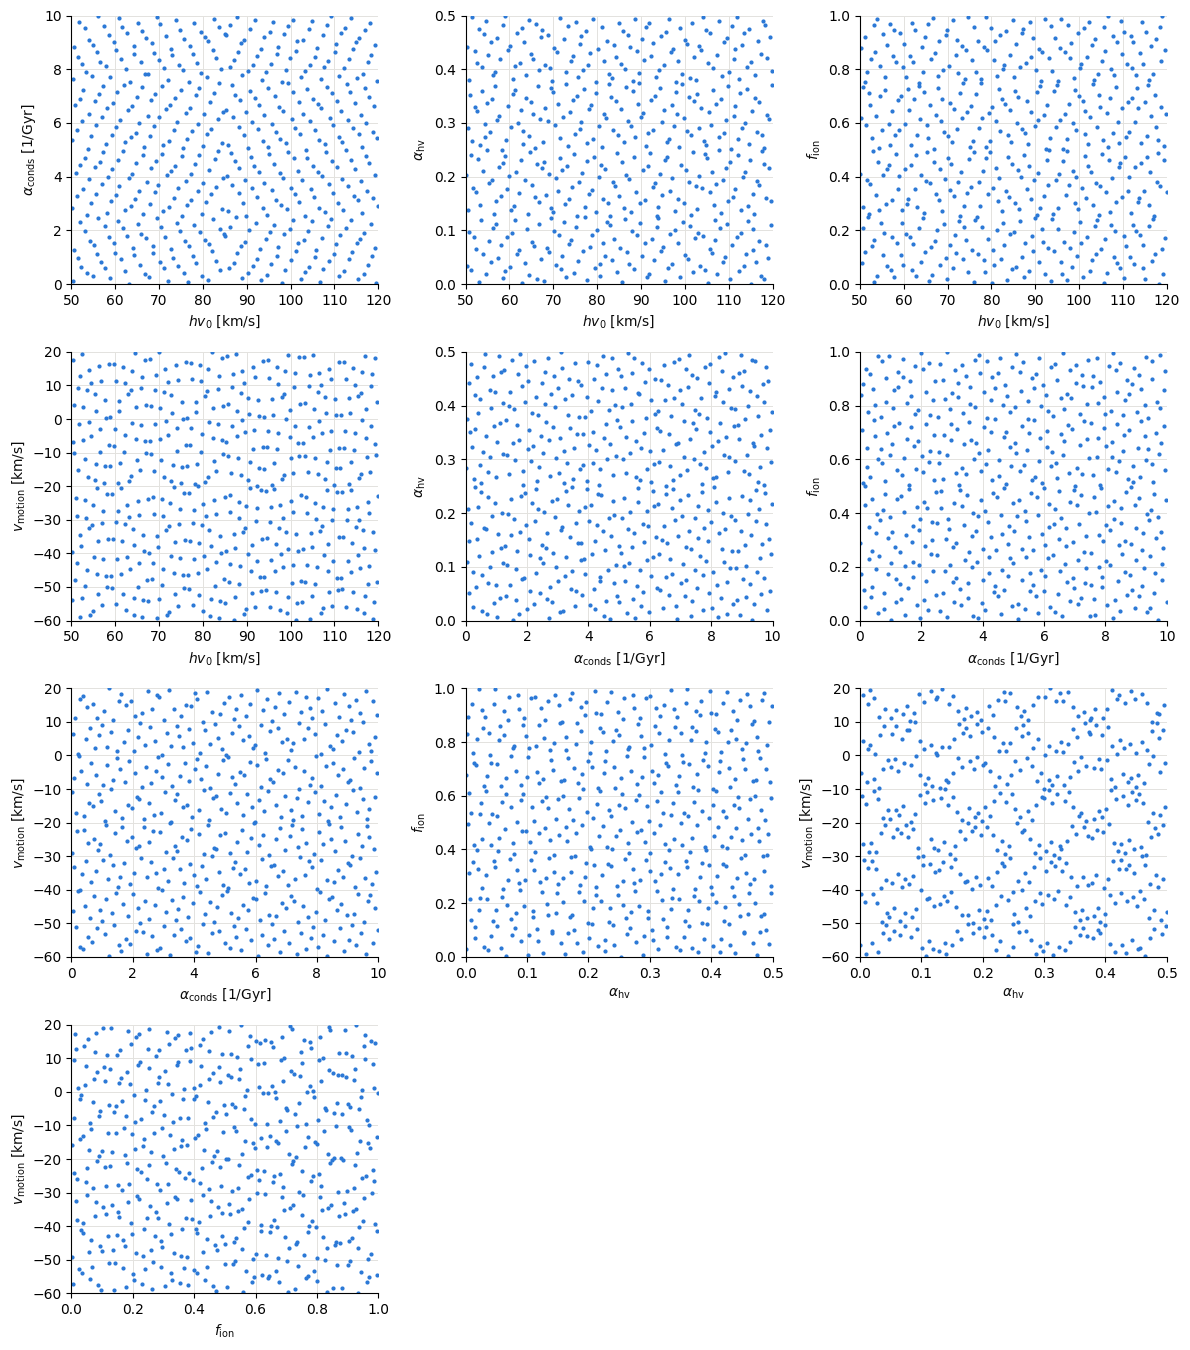

In [6]:
try:
    print("Run file:", g.save_runs(runs, RUN_FILE))
except FileExistsError as e:
    print("NOT written:", e)
    print("-> The run file on disk is used from here on; change STAGE (or N_POINTS back) if you wanted a different design.")

runs = g.load_runs(RUN_FILE)
theta = np.array([[runs[k]["kw"][n] for n in box.names] for k in runs])
print(f"{len(runs)} runs in {RUN_FILE.name}; n_per_bin = {sorted({r['kw']['n_per_bin'] for r in runs.values()})}")

gr.plot_design(theta, box)
plt.show()

**How long will it take, and how much memory?** 

From the numbers of the `G1` job itself (the longest $n = 40$ run took 5.8 min on the full machine and the largest worker held 788 MB; the single-run probe before it had said 2.9 min and 0.7 GB, so a full machine is slower than a probe), assuming that time and memory grow in proportion to `n_per_bin` (check this with a probe at $n = 160$ before running a large $n = 160$ stage), `NWORK = 128` workers and longest runs first.

**Step 4:** an asymmetric model is two north-type runs (north and south, one after the other in the same worker), so a run takes **twice** as long as the numbers above, and `gr.job_estimate` includes this (`cost_rel` of the run file). The memory per worker is a little higher than in G1 (the second hemisphere's cube and the stitched sky are held at the same time): `PROBE_MB` in the settings has an estimate; the first job's `job_summary.json` has the real number.


In [7]:
est = gr.job_estimate(runs, PROBE_MIN, PROBE_MB, workers=125, n_probe=PROBE_N, slow=1.0)
need = gr.memory_advice(est, current_gb=256)
print(f"\nAfter the job, out_{STAGE}_0/job_summary.json lists the longest run and the peak memory that were really used: "
      "\nput them into PROBE_MIN, PROBE_MB (settings) for the next estimate.")

512 runs on 125 workers: about 58 min wall (longest run 11.6 min, +0% for a busy machine); memory 128 GB -> request_memory = 167G
memory: models 128 GB at once, packing 56 GB (16 processes of ~3.5 GB) -> request_memory >= 167G; <submit_file>.sub has 256G: enough.

After the job, out_B1_0/job_summary.json lists the longest run and the peak memory that were really used: 
put them into PROBE_MIN, PROBE_MB (settings) for the next estimate.


## 2. Run it on `heron`

Copy the run file next to `run_conv.py` on `heron`, set the stage in `<submit_file>.sub`, submit:

```bash
scp runs/grid4d_B1.json  <redacted_for_privacy>/runs/
# in <submit_file>.sub:   STAGE = B1      (RUNS, the output folder and the log names follow from it)
cd <redacted_for_privacy>;  mkdir -p logs
condor_submit <submit_file>.sub
condor_q --better-analyze
condor_tail -f <jobid>
```

The job starts the 128 workers, **packs the finished cubes itself** (the `--pack` in the `arguments` line of `<submit_file>.sub`), and returns the folder `out_B1_0/`. In it:

* `pack.fits` — the whole grid in one file (about 0.5 MB per model);
* `params_effective.csv` — the parameters each run really used (the job's own record);
* `job_summary.json` — wall time, longest run, peak memory;
* `B1_0000.npz` ... — the native cubes (large; leave them on `heron`, or delete them once you trust the pack);
* `timings/`, `log_worker*.txt` — per-run times and worker logs.

We do **not** call the packing yourself. `pack_grid.py` is only for: joining the packs of several shards, adding later runs to a pack, packing with other settings (another `V_DEV`, `B_CUT`...), and `verify`. If the job log says `packing skipped: radio_beam is missing`, the models are fine and the log tells us the one-line fix to do the packaging ourselves later.

In [ ]:
def copy_cmds(stage):
    print(f'''Copy commands for stage {stage}:

  scp {RUNS_DIR / f"grid4d_{stage}.json"}  {HERON_WORK}/runs/                                   # before the job
  mkdir -p {WORK}/out_{stage}_0
  scp "{HERON_WORK}/out_{stage}_0/pack.fits"  "{HERON_WORK}/out_{stage}_0/params_effective.csv"  "{HERON_WORK}/out_{stage}_0/job_summary.json"  {WORK}/out_{stage}_0/     # after the job
''')

copy_cmds(STAGE)

## 3. Bring the packaged grids

This step reads the pack(s) of all stages found in `WORK/out_*_*/pack.fits` (several shards or stages, the check stage `P1` included, are joined into `WORK/grid_all.fits`). **If nothing has been copied yet, the cell stops here: do steps 1-2 first.**

Three checks, all on the parameters:
1. the pack was made with the same masks and comparison grid as this notebook (`pack.check`);
2. every model in the pack is a run of a run file, with **the same parameters and seeds** (`compare_pack_to_runfile`);
3. the job's own log of what it used (`params_effective.csv`) says that nothing was filled in.

In [9]:
PACK_FILES = sorted(WORK.glob(f"out_{STAGE}_*/pack.fits")) + sorted(WORK.glob(f"out_{P1_STAGE}_*/pack.fits"))

if not PACK_FILES:
    raise RuntimeError(f"No pack.fits found in {WORK}/out_*_*/ : "
                       "run the job (step 2) and copy pack.fits home first (the copy commands are printed above)")

pack = gr.open_packs(PACK_FILES, RES_DIR / "grid_all.fits")

print(f"{len(PACK_FILES)} pack file(s): {[str(f.parent.name) for f in PACK_FILES]}")
print(f"{len(pack)} models; written on {pack.header.get('HOST')} at "
      f"{pack.header.get('CREATED')}; compression: {'lossless' if pack.bits == 0 else str(pack.bits) + ' bits'}")

RUNS_ALL = {}
for f in sorted(RUNS_DIR.glob("grid4d_*.json")):
    RUNS_ALL.update(g.load_runs(f))

print()
for f in PACK_FILES:                                                        # each job's own record against its run file
    csv = f.parent / "params_effective.csv"
    print(f"--- {f.parent.name} ---")
    with pg.GridPack(f) as p1:
        chk = gr.compare_pack_to_runfile(p1, RUNS_ALL, csv=csv if csv.exists() else None)
    if not csv.exists(): print("  (params_effective.csv not copied: only the pack against the run file was checked)")
    summ = f.parent / "job_summary.json"
    if summ.exists():
        s = json.load(open(summ))
        print(f"  job: {s['runs_done']}/{s['runs_in_share']} runs on {s['host']} with {s['workers']} workers, "
              f"wall {s['wall_minutes']} min, longest run {s['longest_run_minutes']} min,\n"
              f"       peak {s['peak_worker_mb']} MB per worker (request_memory hint {s['request_memory_hint_gb']} GB)\n")
        
    assert chk["ok"], "The models of the pack are not the runs of the run file: do not continue."

2 pack file(s): ['out_B1_0', 'out_PB1_0']
592 models; written on leavitt at 2026-10-25T14:42:14; compression: lossless

--- out_B1_0 ---
pack: 512 models; run file(s): 1906 runs; in both: 512.
  params_effective.csv (512 rows, written by the job on heron): same as the run file, nothing filled in..
  -> every model was run with exactly the parameters its run file lists; nothing was filled in.
  job: 512/512 runs on heron8 with 125 workers, wall 38.95 min, longest run 11.26 min,
       peak 941 MB per worker (request_memory hint 150 GB)

--- out_PB1_0 ---
pack: 80 models; run file(s): 1906 runs; in both: 80.
  params_effective.csv (80 rows, written by the job on heron): same as the run file, nothing filled in..
  -> every model was run with exactly the parameters its run file lists; nothing was filled in.
  job: 80/80 runs on heron5 with 125 workers, wall 10.22 min, longest run 9.84 min,
       peak 783 MB per worker (request_memory hint 125 GB)



## 4. Evaluate: all residuals on all models

The LAB side is built exactly as in the convergence study: the same masks, the same comparison grid, the same residual sets. Then **every model of the pack is evaluated once, with every residual key** (`abs`, `sq`, `rel` in the base, `Mrsc` and `Li` sets); the evaluation is cached (the file name carries every setting that changes a residual), so adding a later stage only evaluates the new models.

In [10]:
cmp = MarascoComparison(lab, ax_lab, keep_lab, build_keep, to_full, 
                        CompareConfig(beam_fwhm=8.0, sampling=4.0, dv=8.0), 
                        rel_floor=REL_FLOOR, residual_sets=RESIDUAL_SETS)
cfg = cmp.cfg
KEYS, SETS = list(cmp.keys), list(cmp.sets)
pack.check(cfg=cfg, V_DEV=V_DEV, B_CUT=B_CUT, L_CUT=L_CUT) # raises if the pack was made with other masks / comparison settings

print(f"Comparison grid {len(cmp.v)} channels x {len(cmp.b)} b x {len(cmp.l)} l; pack settings match this notebook.")
print("Residual keys:", KEYS)

Comparison grid 62 channels x 41 b x 90 l; pack settings match this notebook.
Residual keys: ['abs', 'sq', 'rel', 'abs_Mrsc', 'sq_Mrsc', 'rel_Mrsc', 'abs_Li', 'sq_Li', 'rel_Li']


In [11]:
CACHE = RES_DIR / f"grid_resid_{TAG}.pkl"
RES = gr.evaluate_pack(pack, cmp, cache=CACHE, workers=WORKERS)               # every model of the pack, whatever its stage
RUNS_FIT = {k: r for k, r in pack.runs().items() if r["group"] in FIT_STAGES} # the models of the fit
RES_FIT = {k: RES[k] for k in RUNS_FIT}
tab = gr.residual_table(RES_FIT, pack)

print(f"{len(RES)} models evaluated (cache {CACHE.name});\n"
      f"{len(RUNS_FIT)} of them in the fit (stages {FIT_STAGES});\n"
      f"Stages in the pack: {sorted({r['group'] for r in pack.runs().values()})}")

for s in SETS:
    if f"n_sel_{s}" in tab: 
        print(f"> set {s:5s}: {np.mean(tab['n_sel_' + s]):8.0f} voxels selected on avg (of {RES[tab['name'][0]]['n_valid']})")

0 new evaluations in 0 s; 592 models evaluated
592 models evaluated (cache grid_resid_v35_L0_B0_f0.04_T0.04_k2_s3.12.pkl);
512 of them in the fit (stages ('B1', 'B2'));
Stages in the pack: ['B1', 'PB1']
> set Mrsc :    30367 voxels selected on avg (of 160304)
> set Li   :   102291 voxels selected on avg (of 160304)


**First look at how the residuals relate (models of the fit only).**

The best model of each residual (smallest $R$), and how similarly the residuals rank the models. A Spearman rank correlation near 1 means that two residuals are different ways to say the same thing for this grid; a low one means they will put the optimum in different places.

residual   best model              R          hv0  alpha_conds     alpha_hv        f_ion     v_motion   (smallest R)
abs        B1_0268              2840       80.069        5.154        0.101        0.006      -57.263
sq         B1_0268             796.4       80.069        5.154        0.101        0.006      -57.263
rel        B1_0356           1.8e+04       67.538        7.804        0.472        0.201      -54.252
abs_Mrsc   B1_0152              2178       66.210        7.343        0.009        0.138      -59.011
sq_Mrsc    B1_0268             788.5       80.069        5.154        0.101        0.006      -57.263
rel_Mrsc   B1_0320              8474       54.121        9.082        0.465        0.456      -32.543
abs_Li     B1_0268              2743       80.069        5.154        0.101        0.006      -57.263
sq_Li      B1_0268               796       80.069        5.154        0.101        0.006      -57.263
rel_Li     B1_0282         4.855e+04       88.625        8.961     

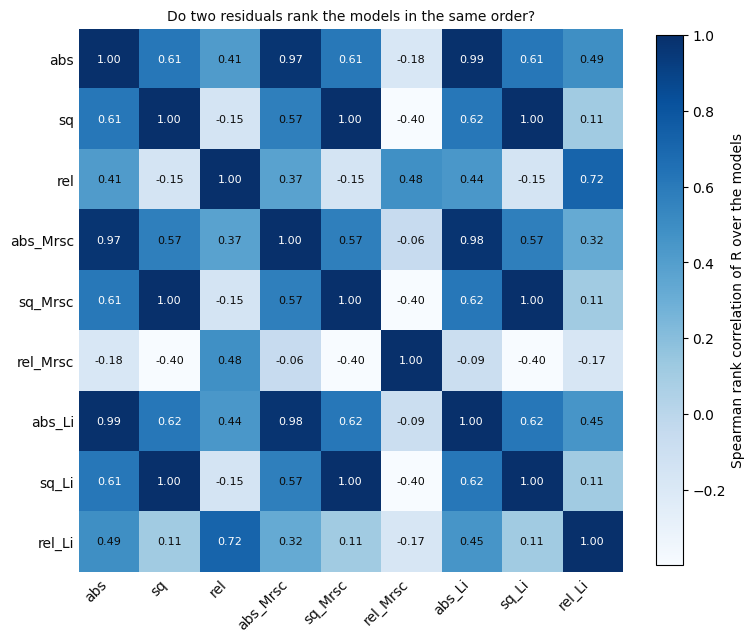

In [12]:
print(f"{'residual':10s} {'best model':12s} {'R':>12s} " + " ".join(f"{n:>12s}" for n in box.names) + "   (smallest R)")
for k in KEYS:
    i = int(np.argmin(tab["R_" + k]))
    print(f"{k:10s} {tab['name'][i]:12s} {tab['R_' + k][i]:12.4g} " + " ".join(f"{tab[n][i]:12.3f}" for n in box.names))
C = gr.rank_correlation(tab, KEYS)
gr.plot_rank_correlation(C, KEYS); plt.show()

## 5. Fit: one surface and one optimum per residual

**The noise of each residual** comes from the convergence study: the relative scatter of $R$ between seeds at $n = 40$ (and at the other $n$, for later stages). If the cache of the convergence study is found it is used (same `TAG`); otherwise the numbers measured there are used (`NOISE_FALLBACK` in `grid_search_residuals.py` as approximates).

*Step 4:* this table is that of the **symmetric** model. The asymmetric one is two runs from the same random numbers; its scatter between seeds should be similar, but it has not been measured (the convergence study was symmetric). The fit has an extra white-noise term, and its size (the table below Section 5) is the place to see whether the assumed noise was too small.


In [13]:
PK_CONV = CONV / f"marasco_conv_{TAG}.pkl" # same tagline. If something new is needed, go back and run convergence.
RES_CONV = pickle.load(open(PK_CONV, "rb")) if PK_CONV.exists() else {}
RES_CONV = {n: r for n, r in RES_CONV.items() if r.get("keys") == KEYS}

GN = {}
for nm in RES_CONV:
    m = re.match(r"N(\d+)_s(\d+)$", nm)
    if m: GN.setdefault(f"N{m[1]}", []).append(nm)

if RES_CONV and len(GN.get("N40", [])) >= 3:
    NOISE = gr.noise_table_from_conv(RES_CONV, GN, KEYS)
    print(f"Noise table from the convergence cache {PK_CONV.name} "
          f"({ {k: len(v) for k, v in sorted(GN.items())} } seeds per n)")
else:
    NOISE = {k: dict(gr.NOISE_FALLBACK[k]) for k in KEYS}
    print("Convergence cache not found: using the noise table measured in the convergence study (gr.NOISE_FALLBACK)")

print(f"{'residual':10s} " + " ".join(f"{'n=' + str(n):>8s}" for n in (10, 20, 40, 80, 160)) + 
      "   (relative std over seeds, %)")

for k in KEYS:
    print(f"{k:10s} " + 
          " ".join(f"{100 * NOISE[k][n]:8.2f}" if n in NOISE[k] else f"{'-':>8s}" for n in (10, 20, 40, 80, 160)))

Noise table from the convergence cache marasco_conv_v35_L0_B0_f0.04_T0.04_k2_s3.12.pkl ({'N10': 6, 'N160': 6, 'N20': 6, 'N320': 2, 'N40': 12, 'N80': 8} seeds per n)
residual       n=10     n=20     n=40     n=80    n=160   (relative std over seeds, %)
abs            2.90     1.44     1.26     0.63     0.30
sq             9.53     3.78     3.95     2.14     1.09
rel            1.18     2.15     0.94     0.60     0.29
abs_Mrsc       3.36     1.48     1.35     0.70     0.31
sq_Mrsc        9.59     3.79     3.97     2.16     1.10
rel_Mrsc       2.30     2.68     1.38     1.31     0.76
abs_Li         2.98     1.44     1.31     0.66     0.30
sq_Li          9.53     3.78     3.95     2.14     1.09
rel_Li         1.55     3.19     1.05     0.70     0.46


**Finite-$n$ bias.** 

Residuals computed with few particles are slightly biased ($R(n) = R_\infty + b/n$). While every run of the fit has the same $n$ (stage `G1` alone) this is a constant offset that does not move the optimum, so we use `USE_BIAS = False`. When a stage with another $n$ (e.g. 160) joins the fit, this now needs to be `True`. $b$ is then fitted per residual from the convergence groups and removed before the logarithm.

In [14]:
USE_BIAS = False
BIAS = {k: gr.fit_bias(RES_CONV, GN, k) for k in KEYS} if (USE_BIAS and RES_CONV) else None
n_levels = sorted({int(r["kw"]["n_per_bin"]) for r in RUNS_FIT.values()})

print("n_per_bin in the fit:", n_levels, "| bias correction:", "on" if BIAS else "off")
if len(n_levels) > 1 and not BIAS:
    print("WARNING: several n_per_bin in the fit and no bias correction: set USE_BIAS = True (needs the convergence cache)")

n_per_bin in the fit: [40] | bias correction: off


**The fit.** 

For every residual key: the Gaussian-process surface (quadratic mean + Matérn-5/2, noise per run from the table above), the posterior of the optimum from joint draws of the surface, and the data-side uncertainty from the leave-one-longitude-sector-out jackknife. This takes about a minute per residual for 512 models in four dimensions (about seven minutes for the 9 residuals); in five dimensions expect roughly twice that.

Then, **the result is stored** (`grid_fit_<TAG>.pkl`) and read back when the models, the residuals and the settings are the same, so re-running the notebook from the top does not repeat it.

In [15]:
OUT = gr.optima_cached(RES_DIR / f"grid_fit_{TAG}.pkl", RES_FIT, RUNS_FIT, KEYS, NOISE, 
                       box, feat, n_draws=200, n_restarts=6, bias=BIAS)
print()
gr.print_optima(OUT)

Fit read from grid_fit_v35_L0_B0_f0.04_T0.04_k2_s3.12.pkl (9 residuals)

residual      n                        hv0                alpha_conds                   alpha_hv                      f_ion                   v_motion                hv(R_pivot)
                 median +- GP +- jackknife  median +- GP +- jackknife  median +- GP +- jackknife  median +- GP +- jackknife  median +- GP +- jackknife  median +- GP +- jackknife
abs         512   67.118 +- 6.898 +-36.860    7.195 +- 0.676 +- 2.983    0.048 +- 0.050 +- 0.436    0.000 +- 0.002 +- 0.000  -55.754 +- 6.252 +-37.084   70.199 +- 7.103 +-74.603
sq          512   90.052 +- 5.037 +- 2.807    2.777 +- 0.268 +- 0.114    0.462 +- 0.017 +- 0.005    1.000 +- 0.012 +- 0.000  -49.171 +- 4.046 +- 0.546  124.746 +- 6.242 +- 3.481
rel         512   88.039 +- 3.276 +- 2.928    9.999 +- 0.343 +- 0.593    0.500 +- 0.000 +- 0.000    0.000 +- 0.000 +- 0.000  -60.000 +- 0.000 +- 0.000  125.528 +- 4.671 +- 4.175
abs_Mrsc    512   62.450 +- 7.848 +-4

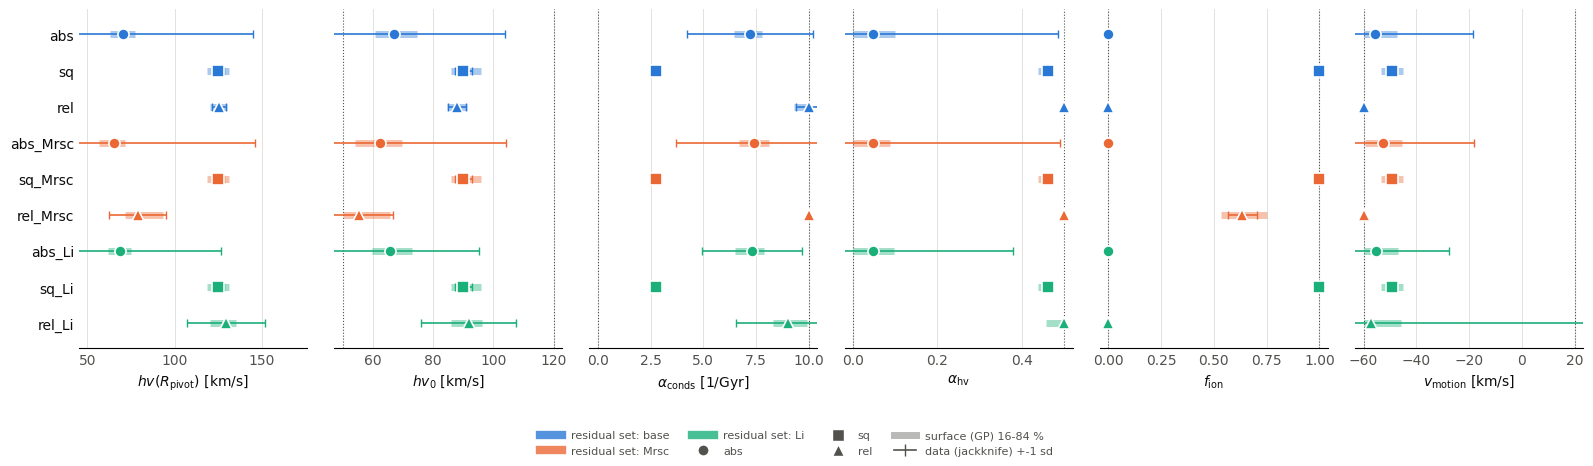

In [16]:
fig = gr.plot_optima(OUT, box, feat=feat)
plt.show()

**Reading the plot.** 

One row per residual, one panel per parameter. 
- The dot is the posterior median of the optimum.
- The thick bar the 16-84 % range from the surface (how well the 512 models pin down the maximum of the fitted surface).
- The whisker the jackknife $\pm 1\sigma$ (how much LAB itself, sector by sector, moves the optimum). 
- Color is the residual set (blue base, orange `Mrsc`, green `Li`).
- Marker is the observable (circle `abs`, square `sq`, triangle `rel`).
- Dotted lines are the edges of the box and the axes end there (a whisker that runs out of the box is cut): an optimum on an edge is a limit, not a value.

**How well-behaved is each surface?** 

Fitted noise scale ($1$ = the noise assumed from the convergence study; much larger means the surface has structure the runs do not explain), leave-one-out $z$ (should have mean $0$, standard deviation $1$), length scales ($4$ = at the bound = flat in that direction) and the share of the optimum's posterior sitting on a box edge. The leave-one-out loop adds about 15 seconds per residual.

In [17]:
ST = gr.surface_table(OUT, box)

residual    runs  noise x  extra         LOO z   length scales (   hv0 alpha_conds alpha_hv  f_ion v_motion)   share at box edge
abs          512     1.27   0.30  -0.00  1.04      (  0.88   1.39   0.93   4.00   1.12)   alpha_hv:lo 28%, f_ion:lo 94%, v_motion:lo 34%
sq           512     0.40   0.00  -0.01  1.16      (  0.66   0.49   0.45   4.00   0.70)   f_ion:hi 86%
rel          512     0.94   0.47  -0.01  1.11      (  0.44   0.91   4.00   3.78   1.79)   alpha_conds:hi 68%, alpha_hv:hi 100%, f_ion:lo 95%, v_motion:lo 99%
abs_Mrsc     512     1.23   0.86  -0.00  1.03      (  0.89   1.32   0.89   4.00   1.08)   alpha_hv:lo 27%, f_ion:lo 88%, v_motion:lo 25%
sq_Mrsc      512     0.40   0.00  -0.01  1.16      (  0.66   0.49   0.45   4.00   0.70)   f_ion:hi 86%
rel_Mrsc     512     1.60   0.70  -0.00  1.08      (  1.18   1.18   1.45   3.45   1.38)   hv0:lo 41%, alpha_conds:hi 99%, alpha_hv:hi 100%, v_motion:lo 100%
abs_Li       512     1.18   0.51  -0.00  1.04      (  0.89   1.39   0.93   4

**One residual in detail.** 

From the residuals we inspect, then we choose the key to get, more in depth. the profiles of its surface along each parameter (grey dots: the evaluated models), the two-parameter slices through its optimum, and the one-sided limits for parameters that sit on an edge.

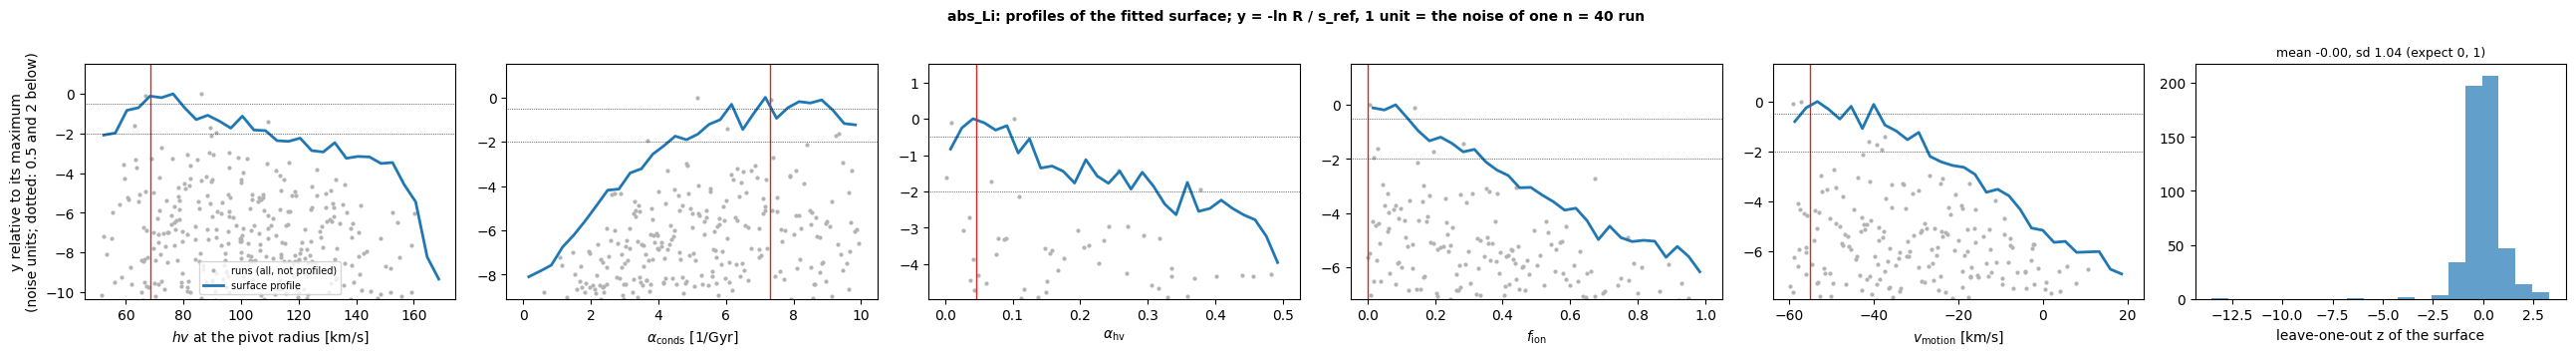

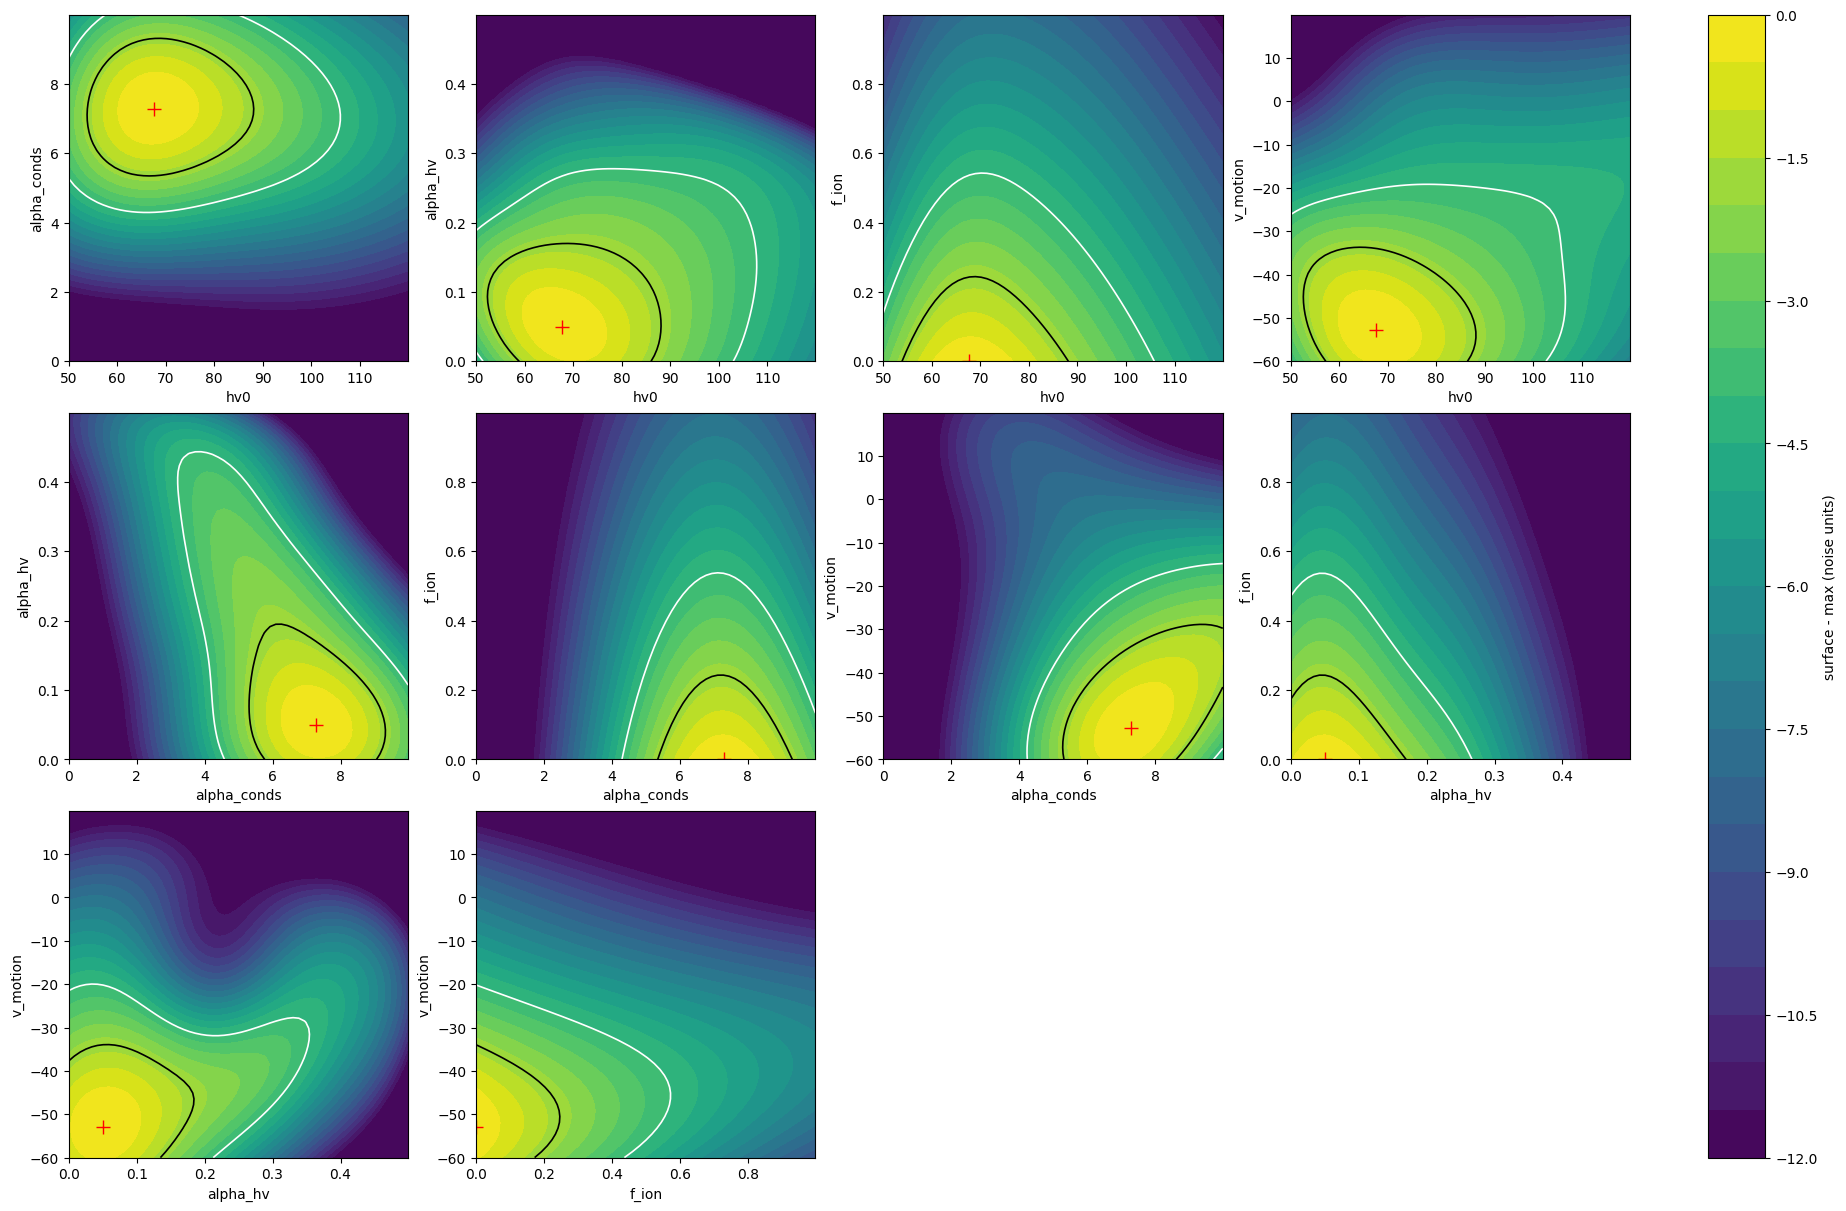

  profile hv_pivot     {0.5: (67.509, 75.06), 2.0: (56.939, 105.262)}
  profile hv0          {0.5: (66.187, 72.311), 2.0: (53.064, 88.059)}
  profile alpha_conds  {0.5: (7.062, 8.687), 2.0: (5.187, 9.937, 'hi-edge')}
  profile alpha_hv     {0.5: (0.028, 0.059), 2.0: (0.003, 0.328, 'lo-edge')}
  profile f_ion        {0.5: (0.006, 0.081, 'lo-edge'), 2.0: (0.006, 0.306, 'lo-edge')}
  profile v_motion     {0.5: (-54.499, -40.5), 2.0: (-59.498, -28.502, 'lo-edge')}


In [18]:
ONE_RESIDUAL = "abs_Li"

KEY = ONE_RESIDUAL if ONE_RESIDUAL in OUT else next(iter(OUT))
o = OUT[KEY]

gr.plot_surface_checks(o, box, feat, KEY)
plt.show()

th_opt = o["est"]["theta_mean_opt"]

fig = g.plot_slices(o["gp"], feat, box, th_opt)
fig.axes[-1].set_ylabel("surface - max (noise units)")
plt.show()

pi = g.profile_intervals(o["gp"], feat, box)
for k, v in pi.items():
    print(f"  profile {k:12s}", 
          {dl: (round(lo, 3), round(hi, 3)) + (("lo-edge",) if elo else ()) + (("hi-edge",) if ehi else ()) \
           for dl, (lo, hi, elo, ehi) in v.items()})

**Save the results** (one row per model with every residual; one row per residual with its optimum and uncertainties).

In [19]:
import csv

with open(RES_DIR / f"grid_table_{TAG}.csv", "w", newline="") as f:
    cols = [c for c in tab if c != "name"]
    w = csv.writer(f); w.writerow(["name"] + cols)
    for i, n in enumerate(tab["name"]): 
        w.writerow([n] + [tab[c][i] for c in cols])

with open(RES_DIR / f"grid_optima_{TAG}.csv", "w", newline="") as f:
    w = csv.writer(f)
    first = next(iter(OUT.values()))
    w.writerow(["residual", "runs"] + [f"{r[0]}_{s}" for r in first["summary"] for s in ("median", "gp_sd", "jackknife_sd")])
    for k, o in OUT.items(): 
        w.writerow([k, len(o["data"]["names"])] + [v for (_, med, a, b, _) in o["summary"] for v in (med, a, b)])

print("Written:", RES_DIR / f"grid_table_{TAG}.csv", "and", RES_DIR / f"grid_optima_{TAG}.csv")

Written: results_B1/grid_table_v35_L0_B0_f0.04_T0.04_k2_s3.12.csv and results_B1/grid_optima_v35_L0_B0_f0.04_T0.04_k2_s3.12.csv


## 5b. Against the symmetric fit (G1)

How far did the asymmetry move the optimum, and how much did it improve the residuals? We read from the tables that the G1 notebook stored in `WORK/results/` (`grid_optima_<TAG>.csv`, `grid_table_<TAG>.csv`), so G1 does not have to be fitted again. If those files are not there, the cell says so and stops: The residual settings (`TAG`) must be the same. Then, the residuals are on the same scale and directly comparable.

* **shift / sd** is the shift of the optimum in units of the combined spread (surface and jackknife of both fits). A shift of the other parameters when `v_motion` or the CGM difference is added is the part of the old optimum that was making up for a missing asymmetry.
* **R of the best models** is the smallest $R$ among the models of each grid and the mean of the ten smallest (less noisy). Smaller is better; the grids are different, so a difference of a few per cent is not yet a statement: the surface-based numbers of section 6.4 are.

In [20]:
import csv

G1_OPT_F = G1_DIR / f"grid_optima_{TAG}.csv"
G1_TAB_F = G1_DIR / f"grid_table_{TAG}.csv"

def _f(x):
    try: return float(x)
    except (TypeError, ValueError): return np.nan

if not (G1_OPT_F.exists() and G1_TAB_F.exists()):
    print(f"The G1 tables are not in {G1_DIR} ({G1_OPT_F.name}, {G1_TAB_F.name}): nothing to compare with. "
          "Copy the 'results' folder of the G1 notebook next to this one.")
else:
    G1_OPT = {r["residual"]: r for r in csv.DictReader(open(G1_OPT_F))}
    G1_TAB = list(csv.DictReader(open(G1_TAB_F)))
    print(f"Optimum of the fit of {STAGE} against the fit of G1 ({len(G1_TAB)} models there, {len(tab['name'])} here)\n")
    print(f"{'residual':9s} {'param':12s} {'G1':>10s} {'this':>10s} {'shift':>9s} {'shift/sd':>9s}")
    for k, o in OUT.items():
        if k not in G1_OPT: continue
        first = True
        for (pname, med, gp_sd, jk_sd, _) in o["summary"]:
            if f"{pname}_median" not in G1_OPT[k]: continue
            m1, g1, j1 = (_f(G1_OPT[k][f"{pname}_{s}"]) for s in ("median", "gp_sd", "jackknife_sd"))
            sd = np.sqrt(sum(np.nan_to_num(x) ** 2 for x in (gp_sd, jk_sd, g1, j1)))
            print(f"{k if first else '':9s} {pname:12s} {m1:10.3f} {med:10.3f} {med - m1:+9.3f} " \
                  + (f"{(med - m1) / sd:+9.1f}" if sd > 0 else f"{'-':>9s}"))
            first = False
        print()

    print(f"{'residual':9s} {'R best, G1':>12s} {'R best, here':>13s} {'mean of 10 best, G1':>20s} "
          f"{'here':>10s} {'change':>8s}")
    for k in KEYS:
        r1 = np.sort([_f(r["R_" + k]) for r in G1_TAB]); r2 = np.sort(np.asarray(tab["R_" + k], float))
        print(f"{k:9s} {r1[0]:12.4g} {r2[0]:13.4g} {r1[:10].mean():20.4g} {r2[:10].mean():10.4g} "
              f"{100 * (r2[:10].mean() / r1[:10].mean() - 1):+7.1f}%")

Optimum of the fit of B1 against the fit of G1 (512 models there, 512 here)

residual  param                G1       this     shift  shift/sd
abs       hv0              83.173     67.118   -16.055      -0.4
          alpha_conds       4.785      7.195    +2.410      +0.6
          alpha_hv          0.444      0.048    -0.396      -0.8
          f_ion             0.000      0.000    +0.000      +0.0
          hv(R_pivot)     112.943     70.199   -42.744      -0.5

sq        hv0              75.108     90.052   +14.943      +1.2
          alpha_conds       9.999      2.777    -7.222      -1.6
          alpha_hv          0.000      0.462    +0.462      +1.8
          f_ion             0.000      1.000    +1.000     +83.2
          hv(R_pivot)      75.523    124.746   +49.223      +2.3

rel       hv0              74.186     88.039   +13.853      +1.1
          alpha_conds       9.999      9.999    +0.000      +0.0
          alpha_hv          0.500      0.500    +0.000      +0.0
          f

## 6. Three checks on the fit

The fit of Step 5 puts several optima on an edge of the box. That is a result about LAB and our model only if the machinery and the box did not make it. 

The three checks below look at the same question from three sides. They need no new model run, except for the direct test in 3b (80 short runs, stage `P1` - we did it, so it is no longer a worry).

| | The Question | Is This due to Physics? | Is This due to our Code? |
|---|---|---|---|
| **1. North / South** | do the two halves of the sky, each with its own flux scale, want the same parameters? | *the same optimum in both (within their surface spread):* the mismatch of model and LAB is the same everywhere | *different optima:* the joint optimum is a compromise between two skies, and a model that is symmetric by construction cannot be right for both |
| **2. A Mock Sky** | if the truth is one of our models (plus noise of LAB's size), does the *same* fit find it? | an interior truth comes back *within about 2 sigma* and is not pushed onto an edge: the machinery is unbiased, so an edge optimum in the real fit belongs to the data | an interior truth that is *pushed onto an edge or missed by many sigma:* the machinery (residual, noise model, surface) is biased and the edge optima of the real fit say nothing yet |
| **3. Marasco's Point** | how much worse than our own optimum is the best fit of Marasco et al. (2012), seen by our residuals? | *a few per cent, the size of the contours in their figures:* both answers sit in the same shallow valley | *large, and confirmed by the direct runs:* at their parameters our model describes LAB clearly worse, so the two models are not the same function of these parameters **(or LAB is compared differently!)** |

The checks use the Li residuals (`abs_Li`, `sq_Li`, `rel_Li`) because those are the ones of the fit with a defined selection and the blanks penalty. We can add keys to `CHECK_KEYS` if we want others (every key costs about a minute per fit). However, check 3 uses all nine keys by default.

In [21]:
CHECK_KEYS = ["abs_Li", "sq_Li", "rel_Li"]                 # residuals of checks 1 and 2
OUT_C = {k: OUT[k] for k in CHECK_KEYS}

### 6.1 North against south

The model is symmetric: the northern cube is mirrored into the south. LAB is not. Herein, every packed model is evaluated once more on **one hemisphere at a time** ($b>0$, $b<0$), with the flux scale fitted on that hemisphere alone, and the same fit is made on each. The models are not run again. The hemisphere fits have no jackknife (the surface spread only); the joint fit (grey) keeps its jackknife whisker.

The evaluation is about as long as step 4, and the fit is about a minute per residual and hemisphere. Both are stored and read back at the next run.

**In step 4 this check is the main question.** `v_motion` is the only *free* north-south asymmetry of the model, so if LAB is asymmetric in a way the symmetric model could not make, `v_motion` will take it up (on top of the fixed CGM difference). Both hemispheres are fitted with the *same* `v_motion` (the south run of the model uses $-v_{\rm motion}$, so one number sets a head wind in one hemisphere and a tail wind in the other): if the asymmetry of LAB is of the kind `v_motion` can make, the two hemispheres should now want **the same** `v_motion` and the other parameters should agree better than in G1. If they do not, the asymmetry of LAB is something else.


0 new evaluations in 0 s; 512 models evaluated
Fit read from grid_fit_north_v35_L0_B0_f0.04_T0.04_k2_s3.12.pkl (3 residuals)
0 new evaluations in 0 s; 512 models evaluated
Fit read from grid_fit_south_v35_L0_B0_f0.04_T0.04_k2_s3.12.pkl (3 residuals)

                                     north              south              joint   north - south (sigma)
abs_Li     hv_pivot        69.852 +- 9.365   116.583 +- 6.645    68.463 +- 6.511       -4.1
           hv0             69.691 +- 8.501    83.282 +- 4.534    65.632 +- 6.649       -1.4
           alpha_conds      9.999 +- 0.019     5.009 +- 0.773     7.311 +- 0.679       +6.5
           alpha_hv         0.000 +- 0.001     0.487 +- 0.021     0.047 +- 0.048      -23.5
           f_ion            0.642 +- 0.119     0.000 +- 0.000     0.000 +- 0.000       +5.4
           v_motion        19.992 +- 4.330   -39.936 +- 9.206   -55.115 +- 6.440       +5.9

sq_Li      hv_pivot        76.692 +-11.221   104.177 +- 7.301   124.742 +- 6.242       -2.1

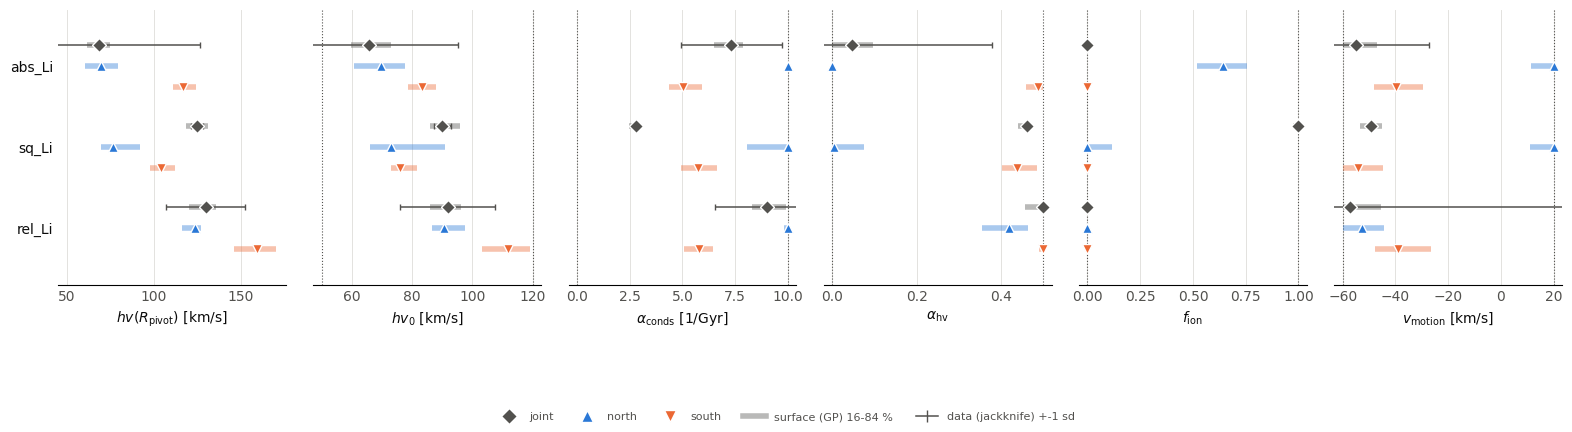

In [22]:
RUN_HEMI = True
if RUN_HEMI:
    HEMI = {"north": lambda B, V, L: B > 0, "south": lambda B, V, L: B < 0}
    GRP = {}

    for hemi, sel in HEMI.items():
        R_h = gr.evaluate_pack(pack, cmp, names=list(RUNS_FIT), 
                               cache=RES_DIR / f"grid_resid_{hemi}_{TAG}.pkl", 
                               workers=WORKERS, fn=gr.subset_evaluator(sel))
        GRP[hemi] = gr.optima_cached(RES_DIR / f"grid_fit_{hemi}_{TAG}.pkl", 
                                     R_h, RUNS_FIT, CHECK_KEYS, NOISE, box, feat, n_draws=200, 
                                     n_restarts=4, jackknife=False, bias=BIAS)
    GRP["joint"] = OUT_C

    print()
    gr.print_comparison({"north": GRP["north"], "south": GRP["south"], "joint": GRP["joint"]}, box, keys=CHECK_KEYS)
    fig = gr.plot_optima_groups({"joint": GRP["joint"], "north": GRP["north"], "south": GRP["south"]}, 
                                box, keys=CHECK_KEYS, feat=feat)
    plt.show()

**Reading it.** 

The last column of the table is the difference of the north and south optimum in units of their combined surface spread (if the spread is zero there, the agreement is the answer). 

In the plot, one row per residual, grey is the both hemispheres together, blue is the north, orange is the south. Two hemispheres on the same edge say that the pull towards that edge does not come from one half of the sky. Two different places say that the joint fit averages two different answers.

### 6.2 A mock sky with a known answer

One packed model plays as the LAB: its cube, scaled to LAB's flux (so the signal is LAB's), plus white Gaussian noise of LAB's size (`SIGMA_NUM`), on the voxels where LAB has data. 

That model is **left out** of the fit (otherwise it would match its own noise exactly). Then, every other model is evaluated against the mock sky with the same residuals, and the fit, the optimum, and the jackknife are the ones of step 5. The truth is the model closest in the unit box to the point asked for, and its true parameters are printed.

Two truths: an **interior** one (the optimum is not near an edge: does the fit find it?) and an **edge** one (near the upper edge of `alpha_conds` and `alpha_hv`: is an edge optimum found, and does the machinery stay on the edge?). One truth takes about a minute of evaluation and three fits (about five minutes), and is stored.

*Two limits:* The noise is white; the real LAB noise is correlated over the beam, so the mock is *optimistic* about the common-mode noise: it tests bias and edges, not the size of the error bars. And the pseudo-LAB is itself an $n = 40$ run, so it carries the particle noise of that run, which no other model shares: a little *pessimistic* in that respect.

=== Mock Sky 'interior': Truth = model B1_0140,
hv0 = 80.3, alpha_conds = 6.32, alpha_hv = 0.294, f_ion = 0.36, v_motion = -40.9
   (asked for {'hv0': 80.0, 'alpha_conds': 5.0, 'alpha_hv': 0.25, 'f_ion': 0.4, 'v_motion': -40.0})

0 new evaluations in 0 s; 511 models evaluated
Fit read from grid_fit_mock_B1_0140_s7_v35_L0_B0_f0.04_T0.04_k2_s3.12.pkl (3 residuals)

residual   param            truth    median  miss %   GP sd   jk sd   pull  edge  jk sd real LAB
abs_Li     hv_pivot        98.963   100.108    +0.9   3.390   2.762   +0.3                58.400
           hv0             80.314    81.963    +2.4   2.574   1.701   +0.5                29.639
           alpha_conds      6.317     6.559    +2.4   0.491   0.324   +0.4                 2.386
           alpha_hv         0.294     0.287    -1.4   0.025   0.030   -0.2                 0.331
           f_ion            0.360     0.375    +1.6   0.068   0.031   +0.2                 0.000
           v_motion       -40.913   -38.849    +2.6 

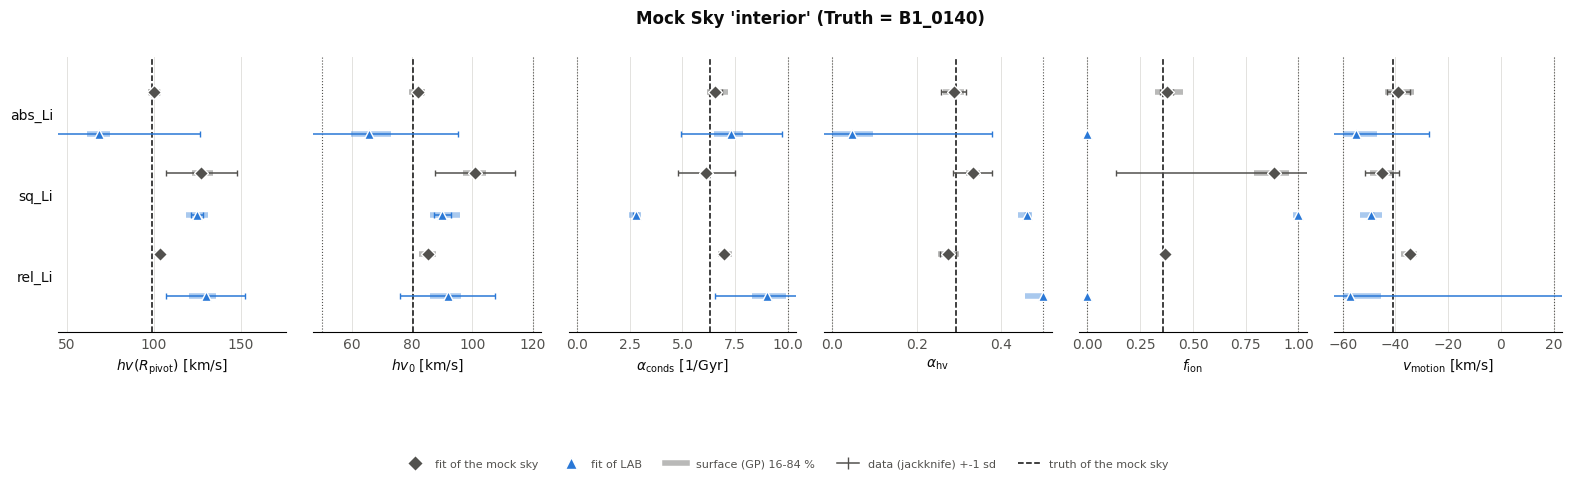

=== Mock Sky 'edge': Truth = model B1_0108,
hv0 = 77, alpha_conds = 8.86, alpha_hv = 0.364, f_ion = 0.113, v_motion = -36.2
   (asked for {'hv0': 75.0, 'alpha_conds': 9.5, 'alpha_hv': 0.45, 'f_ion': 0.05, 'v_motion': -40.0})

0 new evaluations in 0 s; 511 models evaluated
Fit read from grid_fit_mock_B1_0108_s7_v35_L0_B0_f0.04_T0.04_k2_s3.12.pkl (3 residuals)

residual   param            truth    median  miss %   GP sd   jk sd   pull  edge  jk sd real LAB
abs_Li     hv_pivot        99.717    95.735    -3.3   2.732   3.186   -0.9                58.400
           hv0             77.014    75.453    -2.2   2.041   1.547   -0.6                29.639
           alpha_conds      8.862     8.372    -4.9   0.181   0.115   -2.3                 2.386
           alpha_hv         0.364     0.336    -5.6   0.014   0.018   -1.2                 0.331
           f_ion            0.113     0.000   -11.3   0.000   0.000      -    lo           0.000
           v_motion       -36.236   -39.078    -3.6   1.

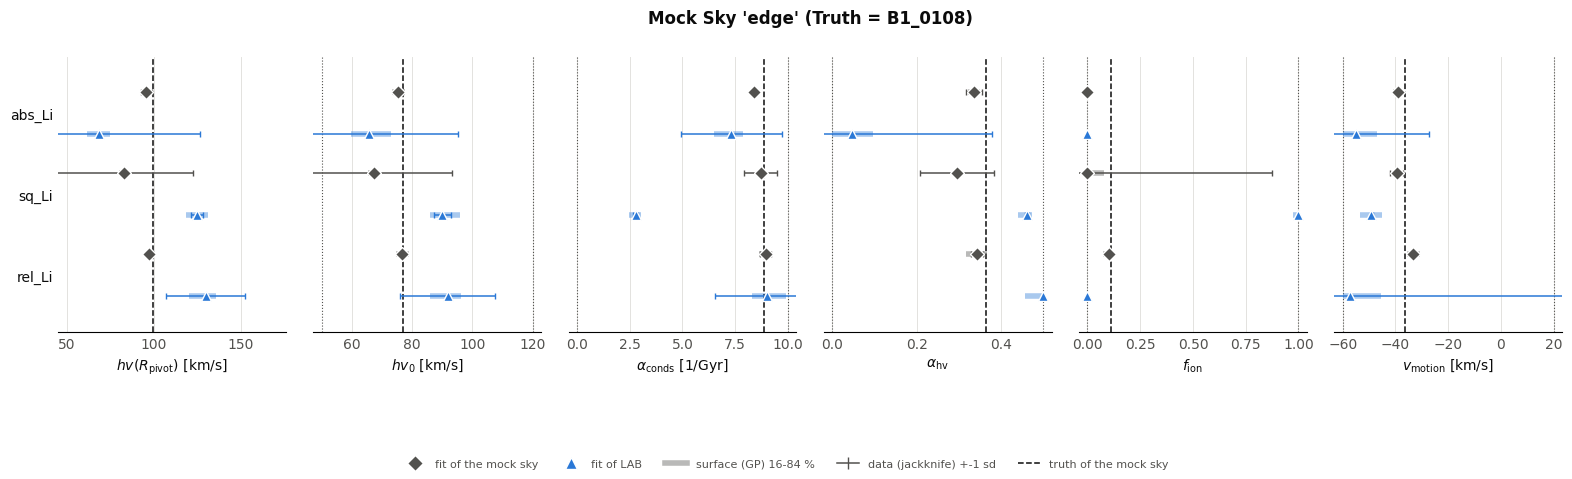

=== Mock Sky 'symmetric': Truth = model B1_0099,
hv0 = 84.6, alpha_conds = 3.96, alpha_hv = 0.245, f_ion = 0.449, v_motion = 3.82
   (asked for {'hv0': 80.0, 'alpha_conds': 5.0, 'alpha_hv': 0.25, 'f_ion': 0.4, 'v_motion': 0.0})

0 new evaluations in 0 s; 511 models evaluated
Fit read from grid_fit_mock_B1_0099_s7_v35_L0_B0_f0.04_T0.04_k2_s3.12.pkl (3 residuals)

residual   param            truth    median  miss %   GP sd   jk sd   pull  edge  jk sd real LAB
abs_Li     hv_pivot       100.681   102.796    +1.7   2.136   1.752   +0.8                58.400
           hv0             84.632    87.575    +4.2   1.855   1.521   +1.2                29.639
           alpha_conds      3.962     4.257    +3.0   0.200   0.095   +1.3                 2.386
           alpha_hv         0.245     0.226    -3.8   0.015   0.009   -1.1                 0.331
           f_ion            0.449     0.494    +4.5   0.030   0.023   +1.2                 0.000
           v_motion         3.819     1.543    -2.8  

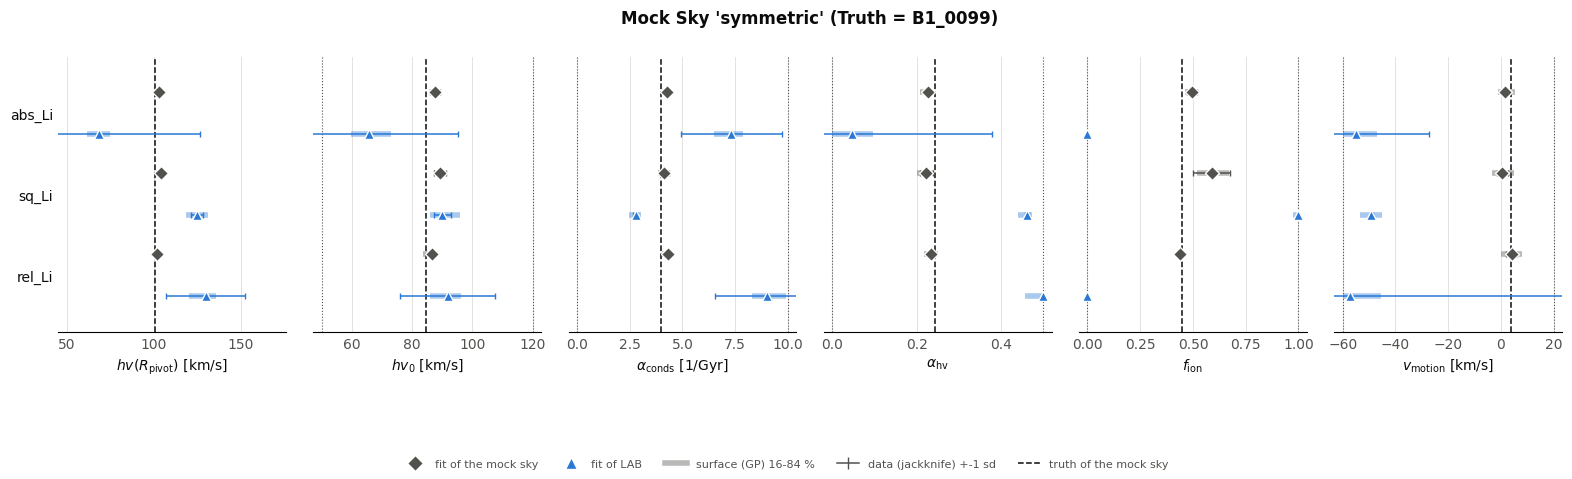

In [23]:
RUN_MOCK  = True
MOCK_SEED = 7                                              # seed of the noise of the mock sky
MOCK_TRUTHS = {"interior":  dict(hv0=80.0, alpha_conds=5.0, alpha_hv=0.25, f_ion=0.4,  v_motion=-40.0),     # Oprea et al.: about -40
               "edge":      dict(hv0=75.0, alpha_conds=9.5, alpha_hv=0.45, f_ion=0.05, v_motion=-40.0),
               "symmetric": dict(hv0=80.0, alpha_conds=5.0, alpha_hv=0.25, f_ion=0.4,  v_motion=0.0)}      # no motion in the sky: does the fit invent one?

MOCK = {}
if RUN_MOCK:
    for label, target in MOCK_TRUTHS.items():
        tn, tth = gr.nearest_model(RUNS_FIT, target, box)
        print(f"=== Mock Sky '{label}': Truth = model {tn},\n" + 
              ", ".join(f"{n} = {v:.3g}" for n, v in zip(box.names, tth)) + 
              f"\n   (asked for { {k: v for k, v in target.items()} })\n")
        
        mcmp = gr.mock_comparison(cmp, pack, tn, scale=RES[tn]["scale"], sigma=SIGMA_NUM, seed=MOCK_SEED)
        names = [n for n in RUNS_FIT if n != tn]
        stem = f"mock_{tn}_s{MOCK_SEED}_{TAG}"

        R_m = gr.evaluate_pack(pack, mcmp, names=names, cache=RES_DIR / f"grid_resid_{stem}.pkl", 
                               workers=WORKERS)
        OM = gr.optima_cached(RES_DIR / f"grid_fit_{stem}.pkl", R_m, {n: RUNS_FIT[n] for n in names}, 
                              CHECK_KEYS, NOISE, box, feat, n_draws=200, n_restarts=4, bias=BIAS)
        
        MOCK[label] = (tn, tth, OM)
        print()

        gr.print_recovery(OM, box, feat, tth, real=OUT_C)
        truth = {n: float(v) for n, v in zip(box.names, tth)}
        truth["hv_pivot"] = float(feat.hv_pivot(np.asarray(tth)[None, :])[0])

        fig = gr.plot_optima_groups({"fit of the mock sky": OM, "fit of LAB": OUT_C}, box, keys=CHECK_KEYS, 
                                    feat=feat, truth=truth)
        
        fig.suptitle(f"Mock Sky '{label}' (Truth = {tn})", color="#0b0b0b", y=0.98, weight="bold")
        plt.show()

**Reading it.** 

- `miss %` = (median $-$ truth) as a percentage of the width of the box (for `hv_pivot` of its range). 
- `pull` = (median $-$ truth) / combined surface and jackknife spread, $|{\rm pull}|\lesssim 2$ means recovered. It is not printed (`-`) where the optimum is pinned, e.g. on an edge, because a spread of zero makes any pull meaningless: there `miss %` and `edge` are what counts. 
- `edge` marks an optimum within 3 % of the box width of an edge. 
- `jk sd real LAB` is the jackknife spread of the same parameter in the real fit: if it is far above the mock's, LAB has structure by sector that no model of this family reproduces, even before asking where the optimum is. 

In the plot, the dashed line is the truth, grey the fit of the mock sky, and blue the fit of LAB.

> We see that the pull on `v_motion` is much higher for exterior than for interior truths. However, the numbers are slightly more improved than the only-motion run.

### 6.3 Marasco's point in our surface

Marasco et al. (2012) fix $hv_0 = 70$ km/s, a constant ejection velocity, $f_{\rm ion} = 0.3$ and find the best $\alpha_{\rm conds} = 6.3$ Gyr $^{-1}$. In our parametrisation that is the point below (`alpha_hv = 0` is taken to be a constant ejection velocity, as the pivot formula $hv_0\,({\rm SFRD}(R_0)/{\rm SFRD}(1\,{\rm kpc}))^{\alpha_{\rm hv}}$ gives). Their $v_{\rm lag}$ and drag are in our fixed parameters (`vlag = 75`).

**3a. On the fitted surface.** For every residual: the surface at that point minus the surface at its own optimum, with the uncertainty from the joint surface covariance of the two points, and the equivalent excess of $R$ in per cent, $R(\text{point})/R(\text{optimum}) - 1$. One noise unit is the noise of one $n = 40$ run (about 1 % of $R$, see the table of step 5).

*Step 4:* the point lives in the model family of this surface: the CGM difference of the settings (`ASYM_FIXED`) is on, as in every other run of the stage. Marasco et al.'s model has no motion, so `v_motion = 0` at their point (`MARASCO_POINT`); the excess of $R$ over our optimum then includes what `v_motion` buys (6.4).


In [24]:
MARASCO_POINT = dict(hv0=70.0, alpha_conds=6.3, alpha_hv=0.0, f_ion=0.3, v_motion=0.0)    # their model has no motion
PT = gr.point_vs_optimum(OUT, feat, box, MARASCO_POINT)

residual      surface at the point - at the optimum   excess of R at the point
abs           -9.35 +-  1.95 noise units                 +12.49 %
sq           -15.06 +-  4.51 noise units                 +81.17 %
rel          -18.06 +-  2.00 noise units                 +18.53 %
abs_Mrsc     -10.35 +-  2.20 noise units                 +14.98 %
sq_Mrsc      -15.04 +-  4.50 noise units                 +81.57 %
rel_Mrsc     -40.04 +-  3.26 noise units                 +73.52 %
abs_Li        -9.22 +-  1.90 noise units                 +12.85 %
sq_Li        -15.05 +-  4.51 noise units                 +81.16 %
rel_Li        -9.35 +-  1.08 noise units                 +10.34 %


**3b. Direct test on `heron`: the same parameters, eight seeds each.** The surface is a fit; at the edge of the box and where it is flat it can be wrong. So the point of Marasco et al. **and each residual's own optimum** are simply run again, **8 seeds each at $n = 40$**, and the mean $R$ at the two places is compared directly: with about 1 % noise per run the mean of 8 is good to about 0.35 %, so an excess of a few per cent is measured at many sigma. The run file `runs/grid4d_PB1.json` (10 places x 8 = 80 runs, about 12 minutes on `heron`: asymmetric runs cost twice) is written once and never replaced; the optima are the ones of the fit **now**, so if the fit changes later the file is kept and the new optima need a new stage name.

In [25]:
# P1 Stage definition is in the first cell.
P1_FILE = RUNS_DIR / f"grid4d_{P1_STAGE}.json"

if P1_FILE.exists():
    P1_RUNS = g.load_runs(P1_FILE)
    print(f"{P1_FILE.name} exists: loaded, not regenerated")
else:
    P1_POINTS = {"marasco": np.array([MARASCO_POINT[n] for n in box.names])}
    P1_POINTS.update({f"opt_{k}": OUT[k]["est"]["theta_mean_opt"] for k in KEYS})
    P1_RUNS = gr.design_replicates(P1_POINTS, P1_STAGE, P1_N, P1_SEEDS, P1_SEED0, box.names, FIXED)
    clash = gr.seeds_used_elsewhere(RUNS_DIR, P1_STAGE) & {r["seed"] for r in P1_RUNS.values()}

    assert not clash, f"Seeds already used by another stage: {sorted(clash)[:5]}"
    print("Run file:", g.save_runs(P1_RUNS, P1_FILE))

labels = list(dict.fromkeys(re.match(rf"^{P1_STAGE}_(.+)_s\d+$", n)[1] for n in P1_RUNS))

print(f"{len(P1_RUNS)} runs = {len(labels)} places x {len(P1_RUNS) // len(labels)} seeds, "
      f"n_per_bin = {sorted({r['kw']['n_per_bin'] for r in P1_RUNS.values()})}\n")

print(f"{'place':16s} " + " ".join(f"{n:>12s}" for n in box.names) + f" {'hv(R_pivot)':>12s}")

for lab in labels:
    kw = P1_RUNS[f"{P1_STAGE}_{lab}_s0"]["kw"]; th = np.array([[kw[n] for n in box.names]])
    print(f"{lab:16s} " + " ".join(f"{kw[n]:12.3f}" for n in box.names) + f" {feat.hv_pivot(th)[0]:12.2f}")

print()
est1 = gr.job_estimate(P1_RUNS, PROBE_MIN, PROBE_MB, workers=len(P1_RUNS), n_probe=PROBE_N, slow=1.0)
gr.memory_advice(est1, current_gb=256)

print(f"\nOn heron, in mw_grid.sub set   STAGE = {P1_STAGE}   and   NWORK = {len(P1_RUNS)}   "
      "(one worker per run; the 256G are enough), \nthen condor_submit as for G1.")
copy_cmds(P1_STAGE)

grid4d_PB1.json exists: loaded, not regenerated
80 runs = 10 places x 8 seeds, n_per_bin = [40]

place                     hv0  alpha_conds     alpha_hv        f_ion     v_motion  hv(R_pivot)
marasco                70.000        6.300        0.000        0.300        0.000        70.00
opt_abs                68.766        7.202        0.051        0.000      -53.476        71.28
opt_sq                 90.103        2.801        0.463        1.000      -49.088       125.13
opt_rel                88.541        9.999        0.500        0.000      -60.000       126.24
opt_abs_Mrsc           64.664        7.466        0.051        0.000      -51.440        67.05
opt_sq_Mrsc            90.134        2.799        0.463        1.000      -49.098       125.17
opt_rel_Mrsc           57.202        9.999        0.500        0.629      -60.000        81.56
opt_abs_Li             67.623        7.289        0.050        0.000      -52.837        70.06
opt_sq_Li              90.100        2.801      

**3c. After the `P1` job.** We copy the three files back, then run the notebook again from step 3: the pack of `P1` joins the others, its models are evaluated in step 4 and **kept out of the fit** (`FIT_STAGES`), and the cell below compares them. Per residual: $R$ at Marasco's point and at the residual's own optimum (mean $\pm$ standard error of the 8 seeds), the excess in per cent and in noise units, and what the surface predicted in 3a. Before the job has come back the cell only says so.

* direct excess and prediction **agree**: the surface can be trusted at both places, and the excess is the answer to "how far is Marasco's best fit from ours".
* direct excess much **smaller** than predicted: the fitted surface exaggerates the difference (an edge extrapolation); the two places are closer than the fit says.
* direct excess much **larger**: the surface is too flat there; the valley is narrower than the fit shows.

In [26]:
RES_P1 = {n: r for n, r in RES.items() if n.startswith(f"{P1_STAGE}_")}
P1_ROWS = gr.replicate_comparison(RES_P1, P1_STAGE, "marasco", {k: f"opt_{k}" for k in KEYS}, NOISE, predicted=PT)

residual    seeds    R(point)  R(own optimum)         excess  in noise units  surface predicted
abs             8      3175.4          2877.4  +10.35 +-0.69 %      +8.2 +- 0.5    +12.49 +-2.45 %
sq              8      982.01          982.95   -0.10 +-3.08 %      -0.0 +- 0.8   +81.17 +-17.80 %
rel             8       20207           22727  -11.09 +-3.23 %     -11.8 +- 3.4    +18.53 +-1.89 %
abs_Mrsc        8      2482.4          2220.7  +11.78 +-0.83 %      +8.7 +- 0.6    +14.98 +-2.96 %
sq_Mrsc         8      972.89           938.8   +3.63 +-2.49 %      +0.9 +- 0.6   +81.57 +-17.83 %
rel_Mrsc        8       11952           10107  +18.25 +-1.13 %     +13.3 +- 0.8    +73.52 +-4.49 %
abs_Li          8      3054.8          2769.8  +10.29 +-0.82 %      +7.8 +- 0.6    +12.85 +-2.50 %
sq_Li           8      981.49          1964.7  -50.04 +-18.14 %     -12.7 +- 4.6   +81.16 +-17.80 %
rel_Li          8       53060           50987   +4.07 +-3.10 %      +3.9 +- 2.9    +10.34 +-1.14 %


### 6.4 What does `v_motion` take from the other parameters?

This is the question that the Step 4 grid searches are about: *how much of the north-south asymmetry of LAB does the new parameter absorb, and does it move the others in doing so?* For every residual:

* **symmetric slice:** the best the model can do with $v_{\rm motion} = 0$ (the other four parameters free), found on the same surface; the point of the slice that is best is `theta_sym`.

* **excess of $R$:** we measure this at `theta_sym` over the global optimum, in per cent, with the uncertainty from the joint covariance of the two points (the same as 3a). This is what `v_motion` buys. If it is within the noise, the data does not ask for the asymmetry.

* **shift of the other parameters:** between the symmetric optimum and the global one: this is what `v_motion` took from them. A large shift of `hv(R_pivot)`, `alpha_conds`, ... with a small gain is the degeneracy that we fear. A gain without a shift is a clean new degree of freedom.

> We see that this mostly demonstrated for `abs`, with `sq` and `rel` struggling with this.

`V_SLICE` is the value of the slice (0 = no motion). The numbers above 5b (the fit against G1) are the same idea measured with the models of two grids; this one uses one surface and is the one to read.

Slice v_motion = 0 km/s against the global optimum of the surface

residual   v_motion   excess of R at the slice   hv(R_pivot) slice->free   alpha_conds slice->free      alpha_hv slice->free         f_ion slice->free
abs           -53.5          +5.38 % +-  2.30     -4.2 noise units   116.283->71.282      3.903->7.202       0.434->0.051       0.000->0.000  
sq            -49.1         +49.39 % +- 47.27    -10.2 noise units    85.767->125.128     9.999->2.801       0.000->0.463       0.000->1.000  
rel           -60.0          +6.59 % +-  1.96     -6.8 noise units   122.422->126.243     8.888->9.999       0.500->0.500       0.000->0.000  
abs_Mrsc      -51.4          +7.62 % +-  2.96     -5.4 noise units   135.455->67.054      3.680->7.466       0.448->0.051       0.000->0.000  
sq_Mrsc       -49.1         +49.53 % +- 47.37    -10.1 noise units    85.590->125.166     9.999->2.799       0.000->0.463       0.000->1.000  
rel_Mrsc      -60.0         +29.43 % +-  6.43    -18.7 noise units 

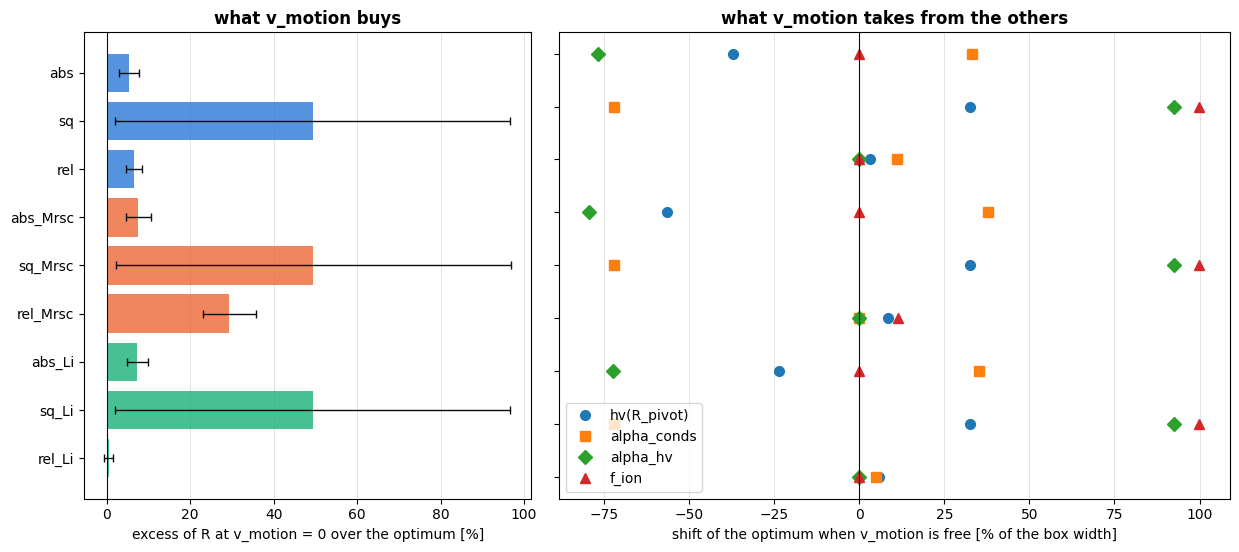

In [27]:
from scipy.optimize import minimize

V_SLICE = 0.0
i_v = box.names.index("v_motion")
u_v = (V_SLICE - box.lo[i_v]) / (box.hi[i_v] - box.lo[i_v])

def slice_optimum(gp, n_cand=16384, n_refine=4, seed=3):
    """ The maximum of the surface mean on the slice v_motion = V_SLICE (same search as grid_search.find_optimum). """
    cand_u = g.sobol_unit(n_cand, box.ndim, seed=seed); cand_u[:, i_v] = u_v
    mean, _ = gp.predict(feat(box.from_unit(cand_u)))
    best_mean, best_u = -np.inf, None
    def neg(x):
        return -gp.predict(feat(box.from_unit(np.insert(np.clip(x, 0.0, 1.0), i_v, u_v))))[0][0]
    for j in np.argsort(-mean)[:n_refine]:
        r = minimize(neg, np.delete(cand_u[j], i_v), method="Nelder-Mead", options=dict(xatol=1e-4, fatol=1e-6, maxiter=400))
        if -r.fun > best_mean:
            best_mean, best_u = -r.fun, np.insert(np.clip(r.x, 0.0, 1.0), i_v, u_v)
    return box.from_unit(best_u)[0], float(best_mean)

SLICE = {}
for k, o in OUT.items():
    th_sym, _ = slice_optimum(o["gp"])
    th_free = np.asarray(o["est"]["theta_mean_opt"], float)
    c = gr.point_vs_optimum({k: o}, feat, box, dict(zip(box.names, th_sym)), verbose=False)[k]
    SLICE[k] = dict(th_sym=th_sym, th_free=th_free, **{q: c[q] for q in ("dy", "sd", "excess_pct", "s_ref")})

show = ["hv(R_pivot)"] + [n for n in box.names if n != "hv0" and n != "v_motion"]
def _val(th, name):
    return float(feat.hv_pivot(np.asarray(th)[None, :])[0]) if name == "hv(R_pivot)" else float(th[box.names.index(name)])

print(f"Slice v_motion = {V_SLICE:g} km/s against the global optimum of the surface\n")
print(f"{'residual':9s} {'v_motion':>9s} {'excess of R at the slice':>26s}   " \
      + "   ".join(f"{n:>11s} slice->free" for n in show))

for k, c in SLICE.items():
    s = c["sd"] * c["s_ref"] * 100 * np.exp(-c["s_ref"] * c["dy"]) # sd of the excess in per cent (linearized).
    print(f"{k:9s} {c['th_free'][i_v]:9.1f} {c['excess_pct']:+14.2f} % +- {s:5.2f} {c['dy']:+8.1f} noise units   "
          + "   ".join(f"{_val(c['th_sym'], n):7.3f}->{_val(c['th_free'], n):<7.3f}" for n in show))

fig, axs = plt.subplots(1, 2, figsize=(12.5, 0.38 * len(SLICE) + 2.2), gridspec_kw=dict(width_ratios=[1, 1.5]))
ks = list(SLICE)[::-1]
cols = [gr.SET_COLORS.get(gr._split_key(k)[1], "#52514e") for k in ks]

ex = np.array([SLICE[k]["excess_pct"] for k in ks])
er = np.array([SLICE[k]["sd"] * SLICE[k]["s_ref"] * 100 * np.exp(-SLICE[k]["s_ref"] * SLICE[k]["dy"]) for k in ks])

axs[0].barh(range(len(ks)), ex, xerr=er, color=cols, alpha=0.8, error_kw=dict(ecolor="#0b0b0b", lw=1, capsize=3))
axs[0].set_yticks(range(len(ks))); axs[0].set_yticklabels(ks); axs[0].axvline(0, color="#0b0b0b", lw=0.8)
axs[0].set_xlabel(f"excess of R at v_motion = {V_SLICE:g} over the optimum [%]") 
axs[0].set_title("what v_motion buys", weight="bold")

width = {n: box.hi[box.names.index(n)] - box.lo[box.names.index(n)] for n in box.names}
for n, mk in zip(show, "osD^v"):
    hv_corners = np.array([[box.lo[j] if (c >> j) & 1 == 0 else box.hi[j]for j in range(box.ndim)] \
                          for c in range(2 ** box.ndim)])
    hv_range = np.ptp(feat.hv_pivot(hv_corners))

    sh = [100 * (_val(SLICE[k]["th_free"], n)- _val(SLICE[k]["th_sym"], n)) / \
          (width[n] if n in width else hv_range) for k in ks]
    
    axs[1].plot(sh, range(len(ks)), mk, ms=7, label=n)

axs[1].axvline(0, color="#0b0b0b", lw=0.8)
axs[1].set_yticks(range(len(ks))); axs[1].set_yticklabels([])
axs[1].set_xlabel("shift of the optimum when v_motion is free [% of the box width]")
axs[1].set_title("what v_motion takes from the others", weight="bold")
axs[1].legend()

for a in axs: 
    a.grid(axis="x", color="#e3e2de", lw=0.7)
    a.set_axisbelow(True)

plt.tight_layout()
plt.show()

## 7. The next stage (optional)

A second batch is placed where the surface of **any** of the chosen residuals could still have its maximum (the union of the plausible regions), not where one favourite residual points: a batch aimed at one residual would starve the others of information and bias the comparison between them. 

We set `PROPOSE = True` to write it. The run file is `runs/grid4d_B2.json`, written once and never replaced.

Then, we repeat from step 1 with `STAGE = "B2"`: set `STAGE` in the settings cell *and* in `<submit_file>.sub`, run the notebook from the top (it will say that stage B1's file is untouched), copy, submit. The new pack joins the old one automatically in step 3, and only the new models are evaluated in step 4.

If the batch is run at $n = 160$ ,the memory per worker is about four times larger (3 GB each, about 350 GB at 128 workers): `request_memory` in `<submit_file>.sub` must be raised to what the estimate printed here says, and a probe at $n = 160$ should come first.

In [28]:
PROPOSE      = False
NEXT_STAGE   = "B2"
NEXT_N       = 40           # 40 = exploration; 160 = refinement (then USE_BIAS = True above, and probe n = 160 first).
NEXT_POINTS  = 128
NEXT_SEED0   = 24000
NEXT_KEYS    = list(OUT)    # the residuals whose plausible regions are joined; shorten the list to focus (e.g. only Li keys).
DELTA        = 4.0          # a point is plausible if it can be within DELTA noise units of the maximum.

if PROPOSE:
    next_file = RUNS_DIR / f"grid4d_{NEXT_STAGE}.json"

    if next_file.exists():
        nruns = g.load_runs(next_file); print(f"{next_file.name} exists: loaded, not regenerated")
        new_theta = np.array([[r["kw"][n] for n in box.names] for r in nruns.values()])

    else:
        new_theta, info = g.propose_batch([OUT[k]["gp"] for k in NEXT_KEYS], feat, box, NEXT_POINTS, delta=DELTA)
        print(f"Proposed {len(new_theta)} points ({info['n_exploit']} where the surfaces may peak, "
              f"{info['n_explore']} exploring); plausible share of the box {info['p_plausible']:.0%}")
        
        nruns = gr.design_runs(new_theta, NEXT_STAGE, NEXT_N, NEXT_SEED0, box.names, FIXED)
        clash = gr.seeds_used_elsewhere(RUNS_DIR, NEXT_STAGE) & {r["seed"] for r in nruns.values()}
        assert not clash, f"Seeds already used by another stage: {sorted(clash)[:5]}"

        print("Run file:", g.save_runs(nruns, next_file))

    gr.print_design(nruns, varied=box.names)
    gr.memory_advice(gr.job_estimate(nruns, PROBE_MIN, PROBE_MB, workers=128, 
                                     n_probe=PROBE_N, slow=1.0), current_gb=256)
    gr.plot_design(pack.theta(names=box.names, subset=list(RUNS_FIT)), box, new=new_theta, 
                   labels=("models so far", "proposed"))
    plt.show()

else:
    print("PROPOSE = False: nothing written")

PROPOSE = False: nothing written
